# Лекция 2. Attention и архитектура трансформера

Курс «Методы обработки естественного языка». Блокнот рассчитан на Google Colab: ячейки выполняются сверху вниз, нужны только torch, numpy и matplotlib (в Colab уже есть). Корпус скачивается автоматически.

Сохранённые выводы получены на CPU в режиме `FAST_DEV_RUN`: Mini-GPT с \(d = 128\), 4 слоями и контекстом 128 символов, по 3000 шагов обучения на вариант. Ветка для GPU в Colab (модель \(d = 384\), 6 слоёв, контекст 256, 5000 шагов) написана, но не проверялась. На ней числа будут другими, переносить стоит направления эффектов.

## Цели лекции

После лекции слушатель должен уметь:

1. объяснить, какое узкое место seq2seq устраняет attention, и записать attention как ядерную регрессию;
2. вывести, почему логиты делят на \(\sqrt{d_k}\), записать якобиан softmax и обратный проход attention;
3. реализовать scaled dot-product и multi-head attention с причинной маской и сверить их с PyTorch;
4. описать блок трансформера: residual stream, Pre-LN и Post-LN, FFN, weight tying; посчитать параметры (\(\approx 12d^2\) на слой) и FLOPs;
5. доказать, что self-attention без позиций эквивариантен к перестановкам, и сравнить синусоидальное, обучаемое, ALiBi, RoPE и NoPE;
6. доказать относительность RoPE \(\langle R_m q, R_n k\rangle = \langle q, R_{n-m}k\rangle\) и объяснить PI и NTK-масштабирование;
7. обучить символьный Mini-GPT и сравнить его с n-граммами и LSTM из лекции 1.

## Как устроен блокнот

Часть I «Теория» (разделы 1–6): от seq2seq к attention, scaled dot-product attention, multi-head attention и residual stream, блок трансформера, позиционное кодирование, семейства архитектур. Часть II «Практикум» (разделы 7–16): attention с нуля и ручной обратный проход, эксперимент с масштабированием, перестановки и регрессия Надарая–Ватсона, MHA, синусоиды и RoPE, Mini-GPT на Tiny Shakespeare в четырёх вариантах, карты внимания, экстраполяция длины, KV-кэш. В конце — выводы, контрольные вопросы, задания и источники.

Практикум соответствует лабораторным 4–5 курса. Здесь показан минимальный рабочий вариант каждого эксперимента, в лабораторных их нужно расширить.

## Данные

Tiny Shakespeare, около 1,1 млн символов ([Karpathy, char-rnn](https://github.com/karpathy/char-rnn)), с тем же разбиением 90/10, что в лекции 1. Поэтому биты на символ Mini-GPT напрямую сравниваются с моделью Кнезера–Ная и LSTM из лекции 1.

## Обозначения

| Символ | Смысл |
|---|---|
| \(X \in \mathbb{R}^{T\times d}\) | входы слоя: \(T\) токенов по \(d\) координат (строки — токены) |
| \(Q, K, V\) | запросы, ключи, значения: \(Q = XW_Q\), \(K = XW_K\), \(V = XW_V\) |
| \(d_k\), \(d_v\), \(d_h\) | размерности ключа, значения, одной головы (\(d_h = d/H\)) |
| \(H\), \(n_{\text{layer}}\) | число голов и слоёв |
| \(S = QK^\top/\sqrt{d_k}\), \(A = \mathrm{softmax}(S + M)\) | логиты и веса внимания, softmax по строкам |
| \(M\) | аддитивная маска: \(0\) или \(-\infty\) |
| \(W_{QK}^h\), \(W_{OV}^h\) | билинейная форма и «канал записи» головы \(h\) |
| \(R_m\), \(\theta_i\) | матрица поворота RoPE для позиции \(m\), частота пары \(i\) |
| bpc | биты на символ, \(-\frac{1}{N}\sum \log_2 p(x_t\mid x_{<t})\) |

# Часть I. Теория

## 1. От seq2seq к attention

### 1.1. Узкое место кодировщика-декодировщика

В лекции 1 рекуррентная модель сжимала весь префикс в вектор \(h_t\) фиксированной размерности. В машинном переводе на этой идее построена схема encoder–decoder ([Sutskever et al., 2014](https://arxiv.org/abs/1409.3215); [Cho et al., 2014](https://arxiv.org/abs/1406.1078)): кодировщик читает исходное предложение \(x_{1:S}\), декодер порождает перевод, получая на вход только последнее состояние \(c = h_S\). Сколько бы ни было слов в предложении, вся информация о нём проходит через \(d\) чисел. [Bahdanau et al. (2014)](https://arxiv.org/abs/1409.0473) предположили, что именно вектор фиксированной длины — узкое место этой архитектуры, и предложили декодеру на каждом шаге «мягко искать» нужные части исходного предложения.

### 1.2. Аддитивное внимание Багданау

На шаге \(t\) декодер со состоянием \(s_{t-1}\) оценивает каждое состояние кодировщика \(h_j\), нормирует оценки и берёт взвешенное среднее:

\[
e_{tj} = v^\top \tanh(W s_{t-1} + U h_j),\qquad
\alpha_{tj} = \frac{\exp e_{tj}}{\sum_{l} \exp e_{tl}},\qquad
c_t = \sum_j \alpha_{tj}\, h_j .
\]

Вектор контекста \(c_t\) свой на каждом шаге, а веса \(\alpha_{tj}\) интерпретируются как мягкое выравнивание слов перевода и оригинала. Путь градиента от \(y_t\) до любого \(h_j\) теперь имеет длину 1, а не \(S - j\): проблема затухания, разобранная в лекции 1, для связи «вход–выход» исчезает. [Luong et al. (2015)](https://arxiv.org/abs/1508.04025) заменили аддитивную оценку мультипликативной \(e_{tj} = s_t^\top W h_j\), из которой и вырос dot-product attention.

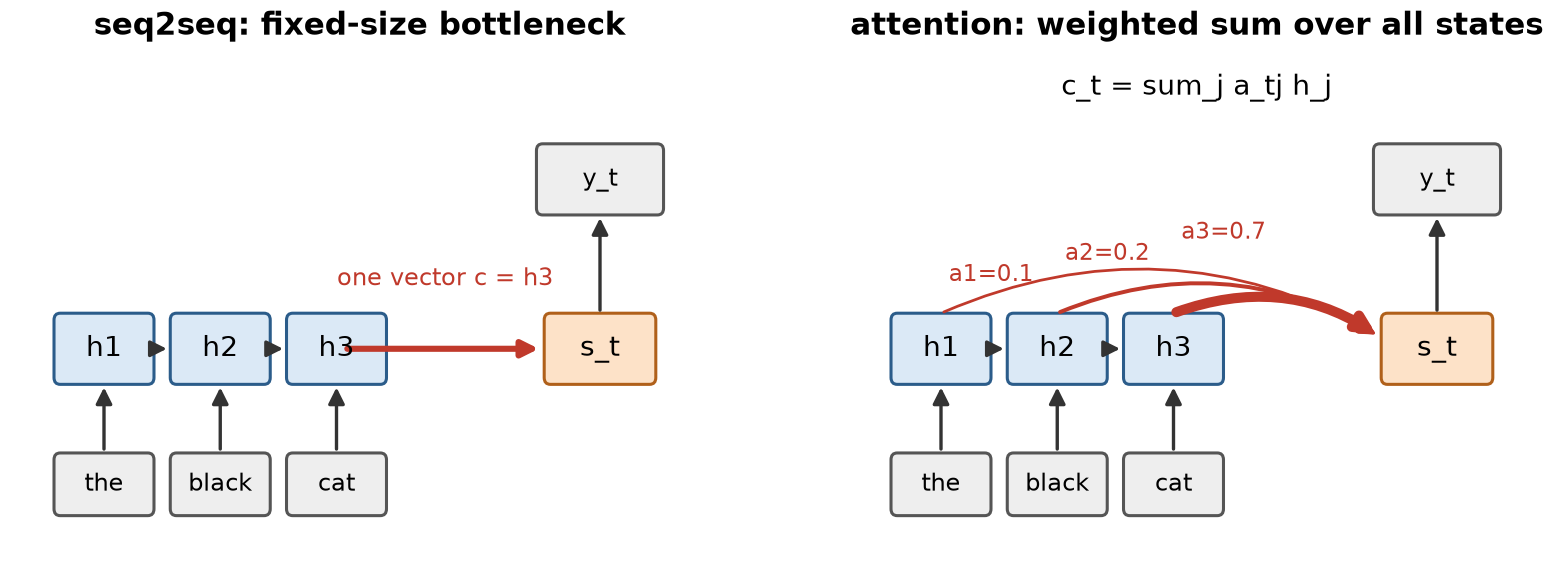

### 1.3. Attention как мягкий поиск по словарю и ядерная регрессия

Обобщим. Есть набор пар «ключ–значение» \((k_j, v_j)\) и запрос \(q\). Жёсткий словарь возвращает \(v_j\) для ключа, совпавшего с запросом. Attention возвращает выпуклую комбинацию всех значений с весами, растущими со сходством запроса и ключа:

\[
\mathrm{Att}(q, \{k_j, v_j\}) = \sum_j \frac{\exp(\mathrm{sim}(q, k_j))}{\sum_l \exp(\mathrm{sim}(q, k_l))}\, v_j .
\]

Это старая идея непараметрической статистики. Оценка регрессии Надарая–Ватсона ([Nadaraya, 1964](https://doi.org/10.1137/1109020)) с ядром \(K\) имеет вид \(\hat f(x) = \sum_i K(x - x_i)\, y_i / \sum_j K(x - x_j)\). Для гауссова ядра \(K(u) = \exp(-u^2/2h^2)\) это attention с \(\mathrm{sim}(x, x_i) = -(x - x_i)^2/2h^2\). Раскрыв квадрат, получаем скалярное произведение \(q^\top k_i\) с \(q = (x, 1)/h\), \(k_i = (x_i, -x_i^2/2)/h\): слагаемое \(-x^2/2h^2\) от \(i\) не зависит и сокращается в softmax (проверка в разделе 10.2). Ширина ядра \(h\) играет роль температуры: малое \(h\) даёт почти one-hot веса и переобучение, большое — сглаживание к среднему. Такую трактовку attention как «attention pooling» подробно разбирает учебник [Dive into Deep Learning](https://d2l.ai/chapter_attention-mechanisms-and-transformers/attention-pooling.html).

Отличие трансформера от ядерной регрессии в том, что запросы, ключи и значения не даны, а вычисляются из входов обучаемыми проекциями, и «ядро» тем самым тоже обучается.

## 2. Scaled dot-product attention

### 2.1. Матричная форма

Пусть \(Q \in \mathbb{R}^{T_q\times d_k}\), \(K \in \mathbb{R}^{T_k\times d_k}\), \(V \in \mathbb{R}^{T_k\times d_v}\) — запросы, ключи и значения по строкам. Тогда ([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762))

\[
\mathrm{Attention}(Q, K, V) = \mathrm{softmax}\!\Big(\frac{QK^\top}{\sqrt{d_k}} + M\Big) V ,
\]

softmax берётся по каждой строке, \(M\) — маска. В self-attention \(Q = XW_Q\), \(K = XW_K\), \(V = XW_V\) из одной и той же последовательности \(X\); в cross-attention (декодер смотрит на кодировщик) запросы берутся из одной последовательности, а ключи и значения — из другой.

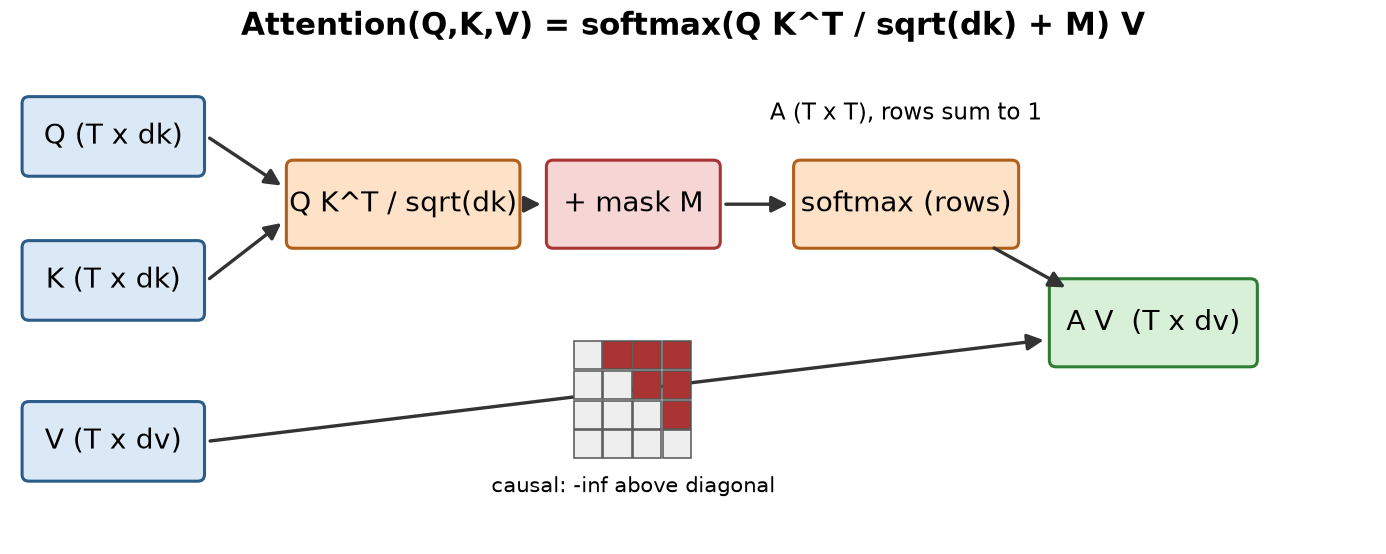

### 2.2. Почему делим на \(\sqrt{d_k}\)

Пусть компоненты \(q\) и \(k\) независимы, со средним 0 и дисперсией 1. Тогда

\[
\mathbb{E}[q^\top k] = \sum_{i=1}^{d_k} \mathbb{E}[q_i]\,\mathbb{E}[k_i] = 0,\qquad
\mathrm{Var}(q^\top k) = \sum_{i=1}^{d_k} \mathbb{E}[q_i^2]\,\mathbb{E}[k_i^2] = d_k .
\]

Это рассуждение приведено в сноске 4 статьи [Vaswani et al. (2017)](https://arxiv.org/abs/1706.03762). Стандартное отклонение логитов растёт как \(\sqrt{d_k}\). При \(d_k = 1024\) типичная разница между логитами — десятки единиц, и softmax почти всегда выдаёт вектор, близкий к one-hot. Деление на \(\sqrt{d_k}\) возвращает дисперсию логитов к 1 при любой размерности головы. Почему насыщенный softmax плох, показывает его якобиан.

### 2.3. Якобиан softmax и обратный проход

Для \(a = \mathrm{softmax}(z)\): \(\partial a_i/\partial z_j = a_i(\delta_{ij} - a_j)\), то есть

\[
J = \mathrm{diag}(a) - a a^\top .
\]

Свойства:

1. \(J\) симметрична и неотрицательно определена: \(u^\top J u = \sum_i a_i u_i^2 - (\sum_i a_i u_i)^2 = \mathrm{Var}_{i\sim a}(u_i) \ge 0\). Иначе говоря, \(J\) — ковариационная матрица one-hot вектора, выбранного по распределению \(a\).
2. \(J\mathbf{1} = a - a(a^\top\mathbf{1}) = 0\): сдвиг всех логитов на константу ничего не меняет.
3. \(\|J\|_2 \le 1/2\). Для единичного \(u\) по неравенству Поповичу \(\mathrm{Var}(u_i) \le (\max u - \min u)^2/4\), а при \(\|u\|_2 = 1\) имеем \((u_i - u_j)^2 \le 2(u_i^2 + u_j^2) \le 2\). Граница достигается при \(a = (\tfrac12, \tfrac12, 0, \dots)\).
4. Если \(a\) близко к one-hot, все элементы \(J\) близки к нулю: \(a_i(1 - a_i) \approx 0\) и \(a_ia_j \approx 0\). Градиент через насыщенный softmax почти не проходит — это и есть вторая причина деления на \(\sqrt{d_k}\) (раздел 9).

Обратный проход attention. Пусть \(O = AV\), \(A = \mathrm{softmax}(S)\) по строкам, \(S = QK^\top/\sqrt{d_k}\), \(G = \partial\mathcal{L}/\partial O\). Из \(O = AV\) получаем \(\partial\mathcal{L}/\partial V = A^\top G\) и \(\partial\mathcal{L}/\partial A = GV^\top\). Softmax действует по строкам, поэтому для строки \(i\) применяем \(J^{(i)}\):

\[
\frac{\partial\mathcal{L}}{\partial S_{ij}} = \sum_l \frac{\partial\mathcal{L}}{\partial A_{il}}\, A_{il}(\delta_{lj} - A_{ij}) = A_{ij}\Big(\frac{\partial\mathcal{L}}{\partial A_{ij}} - \sum_l \frac{\partial\mathcal{L}}{\partial A_{il}} A_{il}\Big).
\]

Наконец, \(\partial\mathcal{L}/\partial Q = (\partial\mathcal{L}/\partial S)\, K/\sqrt{d_k}\) и \(\partial\mathcal{L}/\partial K = (\partial\mathcal{L}/\partial S)^\top Q/\sqrt{d_k}\). Проверка с autograd — в разделе 8.1.

### 2.4. Маски

Маска добавляет \(-\infty\) к запрещённым логитам, после softmax их веса равны нулю.

- Причинная маска: \(M_{ij} = -\infty\) при \(j > i\). Позиция \(i\) видит только себя и прошлое, поэтому одна последовательность длины \(T\) даёт \(T\) обучающих примеров следующего токена за один проход, и при этом модель не подглядывает в будущее.
- Маска паддинга: в батче последовательности разной длины дополняются служебным токеном, на который нельзя смотреть.
- Если в строке замаскировано всё, softmax от строки из \(-\infty\) даёт NaN. В причинной маске такого не бывает: диагональ всегда открыта.

### 2.5. Сложность

Логиты \(QK^\top\) стоят \(2T^2d_k\) FLOPs, умножение \(AV\) — ещё \(2T^2d_v\); матрица \(A\) занимает \(T^2\) чисел на голову. Квадратичная зависимость от длины — главный недостаток attention. Зато все позиции обрабатываются параллельно, а путь сигнала между любыми двумя позициями имеет длину \(O(1)\) против \(O(T)\) у рекуррентной сети ([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762), табл. 1). На практике на GPU узким местом часто оказываются не FLOPs, а чтение и запись \(A\) в память. [FlashAttention](https://arxiv.org/abs/2205.14135) вычисляет точно тот же результат блоками, не материализуя \(A\) целиком; авторы сообщают об ускорении обучения GPT-2 в 3 раза при длине 1K. В PyTorch это доступно через `F.scaled_dot_product_attention`, которую мы используем в Mini-GPT после сверки с ручной реализацией.

## 3. Multi-head attention и residual stream

### 3.1. Несколько голов

Одна голова даёт для каждого запроса одно распределение внимания. Чтобы позиция одновременно смотрела, например, на предыдущий символ и на начало слова, используют \(H\) голов с собственными проекциями размерности \(d_h = d/H\):

\[
\mathrm{head}_h = \mathrm{Attention}(XW_Q^h, XW_K^h, XW_V^h),\qquad
\mathrm{MHA}(X) = [\mathrm{head}_1, \dots, \mathrm{head}_H]\, W_O .
\]

При \(d_h = d/H\) стоимость та же, что у одной головы полной размерности ([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)). В коде все \(W_Q^h\) склеены в одну матрицу \(d\times d\), и разбиение на головы — это просто `view` на \(H\) блоков по \(d_h\) координат.

### 3.2. Матрицы \(W_{QK}\) и \(W_{OV}\)

Логит головы \(h\) между позициями \(i\) и \(j\):

\[
S^h_{ij} = \frac{(x_iW_Q^h)(x_jW_K^h)^\top}{\sqrt{d_h}} = x_i\, \underbrace{\frac{W_Q^h (W_K^h)^\top}{\sqrt{d_h}}}_{W_{QK}^h}\, x_j^\top .
\]

\(W_Q^h\) и \(W_K^h\) входят только через произведение \(W_{QK}^h\) размера \(d\times d\) и ранга не больше \(d_h\). Аналогично вклад головы в выход — \(\sum_j A^h_{ij}\, x_j W_V^h W_O^h\), где \(W_O^h\) — строки \(W_O\), соответствующие голове \(h\), а \(W_{OV}^h = W_V^h W_O^h\) тоже \(d\times d\) ранга \(\le d_h\). В работе [Elhage et al. (2021)](https://transformer-circuits.pub/2021/framework/index.html) это сформулировано так: \(W_{QK}\) решает, откуда переносить информацию, \(W_{OV}\) — что именно читать и как записывать, и эти две задачи полностью разделены. Конкатенация голов с последующим \(W_O\) эквивалентна сумме независимых вкладов голов. Отсюда же видна неединственность параметризации: \(W_Q^h \to W_Q^h B\), \(W_K^h \to W_K^h B^{-\top}\) не меняет модель.

### 3.3. Residual stream

В блоке трансформера каждый подслой прибавляет свой выход к входу: \(x \leftarrow x + f(x)\). После \(L\) блоков

\[
x_L = x_0 + \sum_{l=1}^{L}\big(\mathrm{attn}_l(\cdot) + \mathrm{ffn}_l(\cdot)\big),
\]

то есть итоговое представление — эмбеддинг плюс сумма вкладов всех подслоёв. [Elhage et al. (2021)](https://transformer-circuits.pub/2021/framework/index.html) называют эту сумму residual stream и рассматривают её как канал связи: сам он ничего не вычисляет, все компоненты читают из него линейной проекцией и записывают в него, каждый в своё подпространство. Внимание — единственная операция, которая переносит информацию между позициями; FFN работает с каждой позицией отдельно. Для градиента residual-связь означает прямой путь от потери к любому слою с якобианом \(I + \partial f/\partial x\) вместо произведения якобианов, как в RNN из лекции 1.

## 4. Блок трансформера

### 4.1. Post-LN и Pre-LN

В исходном трансформере нормализация стоит после сложения с residual-связью: \(x \leftarrow \mathrm{LN}(x + f(x))\) (Post-LN). В GPT-2 LayerNorm перенесли на вход каждого подслоя и добавили ещё один после последнего блока ([Radford et al., 2019](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf)): \(x \leftarrow x + f(\mathrm{LN}(x))\) (Pre-LN).

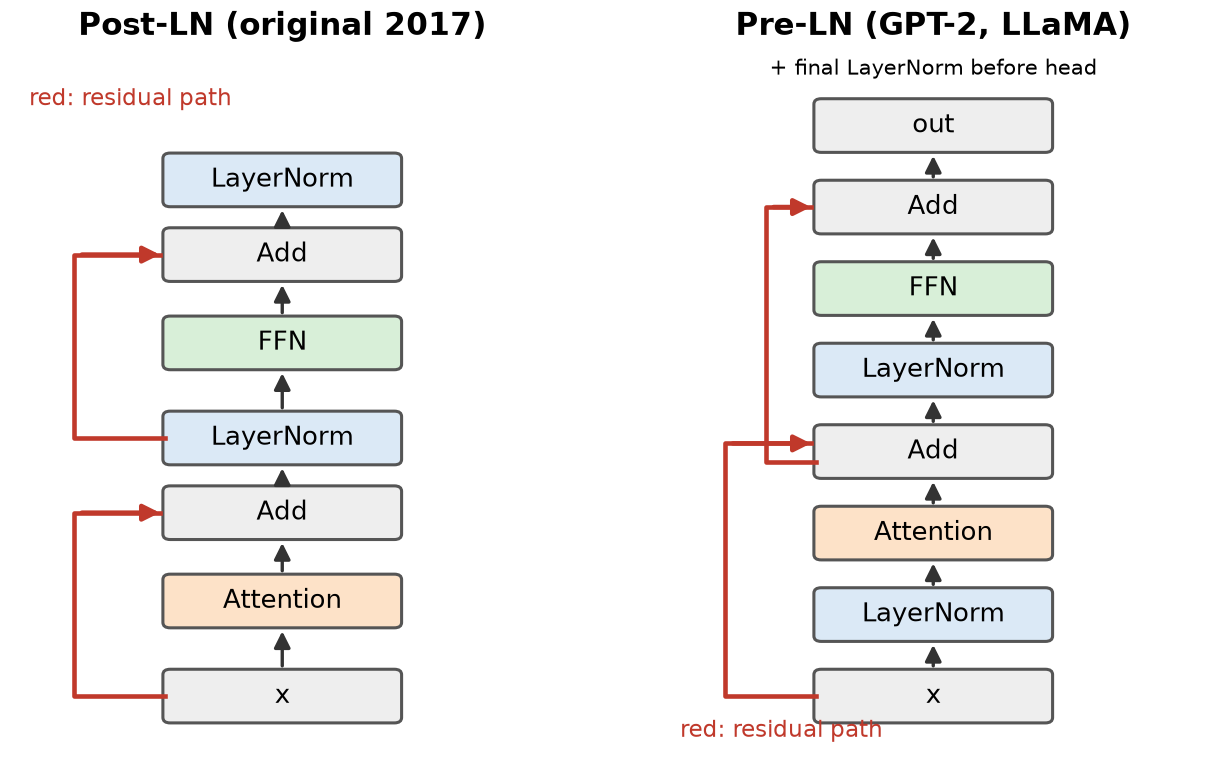

Разница существенна для оптимизации. В Pre-LN residual stream не нормализуется, и путь \(x_0 \to x_L\) — тождественный; градиент потери по \(x_l\) содержит слагаемое \(\partial\mathcal{L}/\partial x_L\) без всяких множителей. В Post-LN каждый LayerNorm стоит на основном пути и масштабирует градиент. [Xiong et al. (2020)](https://arxiv.org/abs/2002.04745) методами теории среднего поля показали, что в Post-LN при инициализации ожидаемые градиенты параметров у выходного слоя велики, поэтому большой learning rate дестабилизирует обучение и нужен прогрев; в Pre-LN градиенты хорошо ведут себя при инициализации, и прогрев можно убрать. Цена Pre-LN — норма residual stream растёт с глубиной, и вклад каждого следующего слоя относительно уменьшается. Отсюда инициализация GPT-2: веса выходных проекций residual-слоёв умножаются на \(1/\sqrt{N}\), где \(N\) — число residual-слоёв ([Radford et al., 2019](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf)). Норму residual stream и градиентов по слоям в обеих схемах мы измерим в разделе 14.1.

### 4.2. LayerNorm и RMSNorm

LayerNorm ([Ba et al., 2016](https://arxiv.org/abs/1607.06450)) нормирует каждый вектор \(x \in \mathbb{R}^d\) по его координатам:

\[
\mathrm{LN}(x) = \gamma \odot \frac{x - \mu}{\sqrt{\sigma^2 + \varepsilon}} + \beta,\qquad \mu = \frac1d\sum_i x_i,\quad \sigma^2 = \frac1d\sum_i (x_i - \mu)^2 .
\]

В отличие от BatchNorm, статистики не зависят от батча и от других позиций, поэтому LayerNorm одинаково работает при обучении и генерации по одному токену. RMSNorm ([Zhang & Sennrich, 2019](https://arxiv.org/abs/1910.07467)) убирает центрирование: \(\mathrm{RMSNorm}(x) = \gamma \odot x/\sqrt{\frac1d\sum_i x_i^2 + \varepsilon}\). Авторы предположили, что инвариантность к сдвигу не нужна, и получили сравнимое качество при сокращении времени работы на 7–64 % на разных моделях. RMSNorm вместе с Pre-LN, SwiGLU и RoPE используется в LLaMA ([Touvron et al., 2023](https://arxiv.org/abs/2302.13971)).

### 4.3. FFN как память

FFN применяется к каждой позиции отдельно: \(\mathrm{FFN}(x) = \phi(xW_1 + b_1)W_2 + b_2\), \(W_1 \in \mathbb{R}^{d\times 4d}\), \(W_2 \in \mathbb{R}^{4d\times d}\), \(\phi\) — ReLU или GELU. Запишем через столбцы \(k_m\) матрицы \(W_1\) и строки \(v_m\) матрицы \(W_2\): \(\mathrm{FFN}(x) = \sum_{m=1}^{4d} \phi(x^\top k_m)\, v_m\). Это неотнормированный аналог attention с \(4d\) обучаемыми «ключами» и «значениями», общими для всех входов. [Geva et al. (2021)](https://arxiv.org/abs/2012.14913) показали, что FFN-слои в языковых моделях работают как память «ключ–значение»: ключи коррелируют с текстовыми шаблонами обучающих примеров, а значения задают распределение над словарём; на FFN приходится две трети параметров модели.

Вариант с гейтом SwiGLU ([Shazeer, 2020](https://arxiv.org/abs/2002.05202)):

\[
\mathrm{FFN}_{\mathrm{SwiGLU}}(x) = \big(\mathrm{Swish}(xW) \odot xV\big) W_2 ,
\]

где \(\mathrm{Swish}(u) = u\,\sigma(u)\). Три матрицы вместо двух, поэтому скрытую размерность уменьшают до \(\tfrac23\cdot 4d\), сохраняя число параметров. Шейзер сообщает, что часть GLU-вариантов улучшает качество по сравнению с ReLU и GELU.

### 4.4. Эмбеддинги и weight tying

Вход — таблица \(E \in \mathbb{R}^{V\times d}\), выход — логиты \(z = h_t W_U\), \(W_U \in \mathbb{R}^{d\times V}\). [Press & Wolf (2017)](https://arxiv.org/abs/1608.05859) показали, что выходная матрица сама является хорошим словарём эмбеддингов, и рекомендовали связывать их, \(W_U = E^\top\): это снижает перплексию и, для моделей перевода, уменьшает их размер более чем вдвое без потери качества. В исходном трансформере одна матрица общая для двух эмбеддингов и выходного слоя перед softmax, а в слоях эмбеддинга веса умножаются на \(\sqrt{d}\) ([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)).

### 4.5. Параметры и вычисления

Блок с \(H\) головами по \(d_h = d/H\) и FFN \(d \to 4d \to d\):

| Часть | Параметры |
|---|---|
| \(W_Q, W_K, W_V, W_O\) со смещениями | \(4d^2 + 4d\) |
| FFN: \(W_1, b_1, W_2, b_2\) | \(8d^2 + 5d\) |
| два LayerNorm (\(\gamma, \beta\)) | \(4d\) |
| итого на блок | \(12d^2 + 13d \approx 12d^2\) |

Модель с \(L\) блоками содержит \(N \approx 12Ld^2\) параметров без эмбеддингов. Например, для GPT-2 small (\(L = 12\), \(d = 768\)) \(12\cdot 12\cdot 768^2 \approx 85\) млн, плюс \(50257\cdot 768 \approx 39\) млн в таблице токенов.

Каждый вес участвует в одном умножении-сложении на токен, поэтому прямой проход стоит около \(2N\) FLOPs на токен плюс слагаемое, зависящее от длины контекста. [Kaplan et al. (2020)](https://arxiv.org/abs/2001.08361) записывают \(C_{\mathrm{forward}} \approx 2N + 2n_{\mathrm{layer}} n_{\mathrm{ctx}} d\), а с учётом обратного прохода (примерно вдвое дороже прямого) — \(C \approx 6N\) FLOPs на обучающий токен; контекстным слагаемым они пренебрегают при \(d \gg n_{\mathrm{ctx}}/12\). Прямой подсчёт обоих умножений \(QK^\top\) и \(AV\) без учёта нулей причинной маски даёт \(4n_{\mathrm{layer}}Td\) на токен. Отношение к \(2\cdot 12 L d^2\) равно \(T/(6d)\): при \(T = d = 128\) это 17 %, то есть для маленьких моделей с относительно длинным контекстом attention-часть уже заметна. Проверка — в разделе 13.1.

## 5. Позиционное кодирование

### 5.1. Self-attention не видит порядка

Пусть \(P\) — матрица перестановки строк. Для self-attention без маски

\[
\mathrm{SA}(PX) = \mathrm{softmax}\!\Big(\frac{PXW_QW_K^\top X^\top P^\top}{\sqrt{d_k}}\Big) PXW_V = P\,\mathrm{softmax}\!\Big(\frac{XW_QW_K^\top X^\top}{\sqrt{d_k}}\Big) P^\top P X W_V = P\,\mathrm{SA}(X),
\]

потому что построчный softmax перестановочен с перестановкой строк и столбцов, а \(P^\top P = I\). FFN и LayerNorm применяются к позициям независимо, следовательно, весь трансформер-кодировщик без позиционной информации эквивариантен к перестановкам: «кот съел мышь» и «мышь съел кот» дают одинаковые наборы выходов. Причинная маска нарушает эквивариантность: позиция \(i\) видит ровно \(i\) токенов. [Haviv et al. (2022)](https://arxiv.org/abs/2203.16634) показали, что причинные языковые модели вообще без позиционного кодирования (NoPE) конкурентоспособны со стандартными и усваивают неявное представление об абсолютных позициях; авторы предполагают, что маска позволяет модели считать число предшественников.

### 5.2. Абсолютные позиции: синусоиды и обучаемая таблица

Синусоидальное кодирование ([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)) прибавляет к эмбеддингу вектор

\[
\mathrm{PE}(m)_{2i} = \sin(m\theta_i),\quad \mathrm{PE}(m)_{2i+1} = \cos(m\theta_i),\qquad \theta_i = 10000^{-2i/d}.
\]

Длины волн образуют геометрическую прогрессию от \(2\pi\) до \(2\pi\cdot 10000\). Авторы выбрали эту функцию в расчёте на то, что модель легко научится смотреть по относительным позициям: при фиксированном сдвиге \(\Delta\) вектор \(\mathrm{PE}(m + \Delta)\) — линейная функция \(\mathrm{PE}(m)\). Действительно, по формулам синуса и косинуса суммы каждая пара \((\sin, \cos)\) поворачивается на угол \(\Delta\theta_i\), и матрица поворота не зависит от \(m\). Кроме того, \(\mathrm{PE}(m)^\top\mathrm{PE}(n) = \sum_i \cos((m - n)\theta_i)\) зависит только от разности. Но после сложения с эмбеддингом и проекций \(W_Q, W_K\) логит содержит перекрёстные члены «содержимое–позиция», и относительность теряется.

Обучаемая таблица позиций (BERT, GPT-2) — просто ещё одна матрица \(L_{\mathrm{ctx}}\times d\). В исходной статье обучаемые и синусоидальные позиции дали почти одинаковые результаты ([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)). Недостаток очевиден: для позиций за пределами \(L_{\mathrm{ctx}}\) векторов просто нет.

### 5.3. RoPE

RoPE ([Su et al., 2021](https://arxiv.org/abs/2104.09864)) ничего не прибавляет к эмбеддингу, а поворачивает запрос и ключ в каждом слое. Для \(d_h = 2\): \(f(q, m) = R_m q\), где \(R_m\) — поворот на угол \(m\theta\). Так как \(R_m^\top = R_{-m}\) и \(R_{-m}R_n = R_{n-m}\),

\[
\langle R_m q, R_n k\rangle = q^\top R_m^\top R_n k = q^\top R_{n-m}\, k = \langle q, R_{n-m}k\rangle .
\]

Логит зависит от содержимого \(q, k\) и только от разности позиций. В комплексной записи \(q, k \in \mathbb{C}\): \(\mathrm{Re}\big[q\,e^{\mathrm{i}m\theta}\,\overline{k\,e^{\mathrm{i}n\theta}}\big] = \mathrm{Re}\big[q\bar k\, e^{\mathrm{i}(m-n)\theta}\big]\). Для \(d_h > 2\) вектор разбивают на \(d_h/2\) пар со своими частотами \(\theta_i = b^{-2i/d_h}\), \(b = 10000\); \(R_m\) — блочно-диагональная матрица поворотов, и тождество выполняется поблочно.

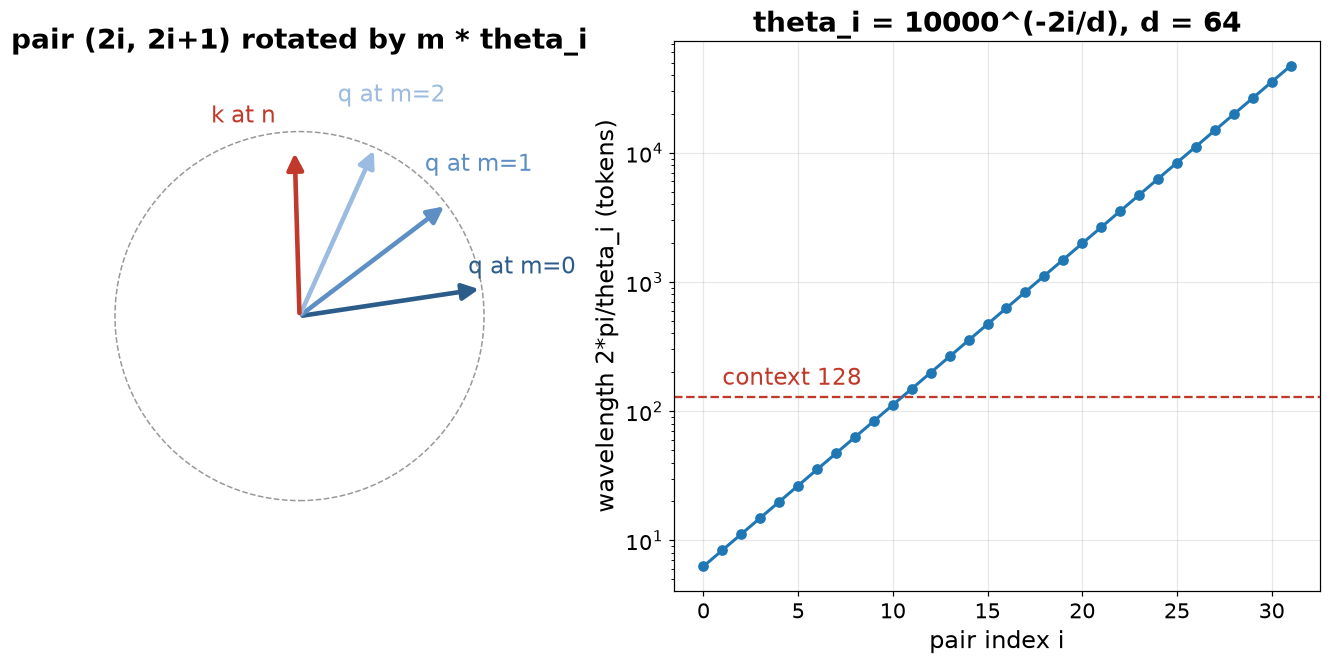

Свойства:

- Поворот ортогонален, нормы \(q\) и \(k\) не меняются; значения \(v\) не поворачиваются.
- Пары с большим \(\theta_i\) (короткая волна) различают соседние позиции, пары с малым \(\theta_i\) почти не поворачиваются на всём контексте и несут «содержательное» сходство. При \(d_h = 32\) и контексте 128 только около трети пар успевают сделать полный оборот (правая панель рисунка построена для \(d_h = 64\)).
- Затухание. Если \(q\) и \(k\) имеют одинаковые компоненты, логит пропорционален \(\sum_i \cos((n - m)\theta_i)\), а модуль этой суммы с ростом \(|n - m|\) в среднем убывает. В статье RoFormer это свойство названо «затуханием межтокенной зависимости с ростом относительного расстояния» и дано верхней оценкой через частичные суммы \(\sum_{i<j} e^{\mathrm{i}(n-m)\theta_i}\) ([Su et al., 2021](https://arxiv.org/abs/2104.09864)). Это свойство «типичного согласованного» вектора, а не закон: для случайных независимых \(q, k\) математическое ожидание логита равно нулю на любом расстоянии (раздел 12.3).

### 5.4. ALiBi

ALiBi ([Press et al., 2021](https://arxiv.org/abs/2108.12409)) не трогает \(q\) и \(k\), а прибавляет к логиту штраф, линейный по расстоянию: \(S_{ij} \leftarrow S_{ij} - \lambda_h (i - j)\), с наклоном \(\lambda_h\) своим для каждой головы (геометрическая прогрессия). Авторы обучили модель 1,3 млрд параметров на длине 1024, и на длине 2048 она достигла той же перплексии, что модель с синусоидами, обученная на 2048, при этом обучалась на 11 % быстрее и требовала на 11 % меньше памяти.

### 5.5. Растяжение контекста RoPE: PI, NTK, YaRN

На позициях больше обученной длины \(L\) пары с низкой частотой впервые проходят углы, которых модель не видела, и качество резко падает (раздел 15.2). Варианты для новой длины \(L' = sL\):

- Position Interpolation ([Chen et al., 2023](https://arxiv.org/abs/2306.15595)): позиции делятся на \(s\), \(m \to m/s\), и все углы остаются в обученном диапазоне. Авторы растянули контекст моделей LLaMA до 32768 токенов, дообучая не более 1000 шагов, и показали, что верхняя оценка ошибки при интерполяции как минимум примерно в 600 раз меньше, чем при экстраполяции. Минус: высокие частоты тоже сжаты в \(s\) раз, соседние токены различаются хуже.
- NTK-aware интерполяция, предложенная в сообществе (bloc97, 2023) и описанная в [YaRN](https://arxiv.org/abs/2309.00071): меняется основание, \(b' = b\, s^{d_h/(d_h-2)}\). Тогда \(\theta_0\) не меняется, а самая низкая частота \(\theta_{d_h/2-1} = b^{-(d_h-2)/d_h}\) уменьшается ровно в \(s\) раз: высокие частоты экстраполируются, низкие интерполируются.
- YaRN ([Peng et al., 2023](https://arxiv.org/abs/2309.00071)) комбинирует интерполяцию по разным частотам и поправку температуры attention; авторы сообщают, что их методу нужно в 10 раз меньше токенов и в 2,5 раза меньше шагов обучения, чем предыдущим.

### 5.6. NoPE и длина

[Kazemnejad et al. (2023)](https://arxiv.org/abs/2305.19466) сравнили схемы на задачах обобщения по длине для декодеров и нашли, что NoPE превосходит явные позиционные кодирования; теоретически NoPE может представлять и абсолютные, и относительные позиции, а при обучении SGD его паттерны внимания похожи на относительные позиции T5. Выводы получены на синтетических и рассуждательных задачах с небольшими моделями, и переносить их на большие языковые модели нужно осторожно. В разделе 15.2 мы проверим это на символьной модели.

## 6. Семейства архитектур и вывод

### 6.1. Encoder, decoder, encoder–decoder

| Семейство | Маска | Обучение | Пример |
|---|---|---|---|
| encoder-only | двунаправленная | восстановление замаскированных токенов (MLM) | BERT ([Devlin et al., 2018](https://arxiv.org/abs/1810.04805)) |
| decoder-only | причинная | следующий токен | GPT-2 ([Radford et al., 2019](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf)), LLaMA ([Touvron et al., 2023](https://arxiv.org/abs/2302.13971)) |
| encoder–decoder | двунаправленная в кодировщике, причинная + cross-attention в декодере | восстановление испорченных фрагментов, «текст в текст» | T5 ([Raffel et al., 2019](https://arxiv.org/abs/1910.10683)) |

BERT маскирует 15 % токенов и предсказывает их по контексту с обеих сторон; представления подходят для классификации и разметки, но генерировать текст такой модели неудобно. Декодер учится на всех позициях сразу и генерирует естественно, поэтому эта схема стала основной для больших языковых моделей. T5 сводит все задачи к формату «текст на входе — текст на выходе».

### 6.2. Генерация и KV-кэш

Генерация авторегрессионна: на шаге \(t\) нужен только новый запрос \(q_t\), а ключи и значения прошлых позиций не меняются (маска причинная). Их хранят в KV-кэше, и шаг стоит \(O(td)\) на слой вместо \(O(t^2d)\) для пересчёта всего префикса. Объём кэша — \(2 n_{\mathrm{layer}} T d\) чисел на последовательность; для длинных контекстов именно память кэша, а не веса, ограничивает размер батча. Для RoPE в кэше хранятся уже повёрнутые ключи, а новому токену передаётся его абсолютная позиция. Реализация и проверка — в разделе 15.3.

# Часть II. Практикум

| Раздел | Что делаем | Связь с теорией |
|---|---|---|
| 7 | настройка, Tiny Shakespeare с тем же разбиением, что в лекции 1 | — |
| 8 | attention с нуля, сверка с `F.scaled_dot_product_attention`, ручной обратный проход | раздел 2 |
| 9 | зачем делить на \(\sqrt{d_k}\): дисперсия логитов, энтропия, якобиан softmax | раздел 2 |
| 10 | перестановочная эквивариантность; attention как ядерная регрессия Надарая–Ватсона | разделы 1, 5 |
| 11 | multi-head attention с нуля, сверка с `nn.MultiheadAttention`, причинность, \(W_{QK}\) | раздел 3 |
| 12 | синусоидальное кодирование и RoPE: относительность, затухание, PI и NTK | раздел 5 |
| 13 | Mini-GPT: модель, подсчёт параметров и FLOPs | раздел 4 |
| 14 | обучение: RoPE, learned, NoPE, Post-LN; residual stream по слоям | разделы 4–5 |
| 15 | анализ: карты внимания, экстраполяция длины, KV-кэш, генерация | разделы 2, 5, 6 |
| 16 | сводная таблица и сравнение с лекцией 1 | все |

## 7. Настройка и данные

Все параметры собраны в словаре `S`. На CPU автоматически включается `FAST_DEV_RUN`: модель \(d=128\), 4 слоя, 4 головы, контекст 128 символов, короткое обучение. На GPU в Colab (`Runtime → Change runtime type → T4 GPU`) модель крупнее: \(d=384\), 6 слоёв, 6 голов, контекст 256, как в символьной конфигурации [nanoGPT](https://github.com/karpathy/nanoGPT). Эта ветка написана, но с сохранёнными выводами не проверялась.

In [1]:
import os, math, time, random, urllib.request
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FAST_DEV_RUN = DEVICE == "cpu"
SEED = 0
T_START = time.time()
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
plt.rcParams.update({"figure.dpi": 100, "font.size": 12, "axes.grid": True, "grid.alpha": 0.3})

S = dict(
    d=128 if FAST_DEV_RUN else 384, n_layer=4 if FAST_DEV_RUN else 6, n_head=4 if FAST_DEV_RUN else 6,
    ctx=128 if FAST_DEV_RUN else 256, bs=32 if FAST_DEV_RUN else 64,
    steps=3000 if FAST_DEV_RUN else 5000, lr=2e-3 if FAST_DEV_RUN else 1e-3, warmup=100, wd=0.1, clip=1.0,
    dropout=0.0 if FAST_DEV_RUN else 0.2, rope_base=10000.0,
)
print(f"device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}, torch {torch.__version__}")
print(S)

device=cpu, FAST_DEV_RUN=True, torch 2.14.1+cpu
{'d': 128, 'n_layer': 4, 'n_head': 4, 'ctx': 128, 'bs': 32, 'steps': 3000, 'lr': 0.002, 'warmup': 100, 'wd': 0.1, 'clip': 1.0, 'dropout': 0.0, 'rope_base': 10000.0}


### 7.1. Корпус

Tiny Shakespeare ([Karpathy, char-rnn](https://github.com/karpathy/char-rnn)) — около 1,1 млн символов. Разбиение такое же, как в лекции 1: первые 90 % текста для обучения, последние 10 % для валидации. Алфавит — 65 символов, токен = символ. Поэтому потеря в битах на символ (bpc) напрямую сравнима с n-граммами Кнезера–Ная и LSTM из лекции 1.

In [2]:
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/shakespeare.txt"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", "data/shakespeare.txt")
SH = open("data/shakespeare.txt", encoding="utf-8").read()
n_sh = int(0.9 * len(SH)); SH_TRAIN, SH_VAL = SH[:n_sh], SH[n_sh:]
CH = sorted(set(SH)); STOI = {ch: i for i, ch in enumerate(CH)}; NV = len(CH)
TR = torch.tensor([STOI[c] for c in SH_TRAIN]); VA = torch.tensor([STOI[c] for c in SH_VAL])
decode = lambda ids: "".join(CH[i] for i in ids)
print(f"обучение {len(TR):,} символов, валидация {len(VA):,}, алфавит {NV}")
print(repr(SH_VAL[:120]))

# Результаты лекции 1 на том же разбиении (CPU, FAST_DEV_RUN), бит на символ на валидации
L1_REF = {"равномерное распределение": math.log2(NV), "Kneser–Ney, n = 6": 2.248, "RNN (tanh), 103 тыс. параметров": 2.262, "LSTM, 351 тыс. параметров": 2.193}

обучение 1,003,854 символов, валидация 111,540, алфавит 65
'?\n\nGREMIO:\nGood morrow, neighbour Baptista.\n\nBAPTISTA:\nGood morrow, neighbour Gremio.\nGod save you, gentlemen!\n\nPETRUCHI'


## 8. Attention с нуля

Реализуем формулу из раздела 2 буквально: логиты \(S = QK^\top/\sqrt{d_k}\), маска, softmax по строкам, взвешенная сумма значений. Маска задаётся булевой матрицей: `True` — разрешённая пара (запрос \(i\), ключ \(j\)). Для причинной маски разрешено \(j \le i\).

Сверяем результат с `F.scaled_dot_product_attention` из PyTorch в двойной точности, без маски и с причинной маской.

In [3]:
def attention(q, k, v, mask=None):
    """q: (..., Tq, dk), k: (..., Tk, dk), v: (..., Tk, dv); mask: bool (Tq, Tk), True = можно смотреть."""
    s = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])
    if mask is not None:
        s = s.masked_fill(~mask, float("-inf"))
    a = s.softmax(dim=-1)
    return a @ v, a

def causal_mask(T, device=None):
    return torch.ones(T, T, dtype=torch.bool, device=device).tril()

g = torch.Generator().manual_seed(0)
B, H, T, dk = 2, 3, 10, 16
q, k, v = (torch.randn(B, H, T, dk, generator=g, dtype=torch.float64) for _ in range(3))
for name, m in [("без маски", None), ("причинная маска", causal_mask(T))]:
    o, a = attention(q, k, v, m)
    ref = F.scaled_dot_product_attention(q, k, v, is_causal=m is not None)
    print(f"{name:16s}: max |ours - torch| = {(o - ref).abs().max():.2e}; суммы строк A: {a.sum(-1).min():.6f}..{a.sum(-1).max():.6f}; "
          f"веса выше диагонали: {0.0 if m is None else a[..., ~m].abs().max().item():.1e}")
print("первая строка A с маской (запрос 0 видит только себя):", attention(q, k, v, causal_mask(T))[1][0, 0, 0, :4].tolist())

без маски       : max |ours - torch| = 4.44e-16; суммы строк A: 1.000000..1.000000; веса выше диагонали: 0.0e+00
причинная маска : max |ours - torch| = 4.44e-16; суммы строк A: 1.000000..1.000000; веса выше диагонали: 0.0e+00
первая строка A с маской (запрос 0 видит только себя): [1.0, 0.0, 0.0, 0.0]


**Что видно.** Наша функция `attention` совпадает с `F.scaled_dot_product_attention` до \(4{,}4\cdot 10^{-16}\) — это округление double. Каждая строка \(A\) суммируется в 1, а с причинной маской все веса выше диагонали в точности нулевые. Первый запрос с маской видит только себя: его строка равна \((1, 0, 0, 0)\).

### 8.1. Обратный проход вручную

Для \(O = AV\), \(A = \mathrm{softmax}(S)\), \(S = QK^\top/\sqrt{d_k}\) и входящего градиента \(G = \partial \mathcal{L}/\partial O\) (вывод в разделе 2.3):

\[
\frac{\partial \mathcal{L}}{\partial V} = A^\top G,\quad
\frac{\partial \mathcal{L}}{\partial A} = G V^\top,\quad
\frac{\partial \mathcal{L}}{\partial S} = A \odot \Big(\frac{\partial \mathcal{L}}{\partial A} - \mathrm{rowsum}\big(\tfrac{\partial \mathcal{L}}{\partial A}\odot A\big)\Big),
\]
\[
\frac{\partial \mathcal{L}}{\partial Q} = \frac{1}{\sqrt{d_k}}\frac{\partial \mathcal{L}}{\partial S}K,\qquad
\frac{\partial \mathcal{L}}{\partial K} = \frac{1}{\sqrt{d_k}}\Big(\frac{\partial \mathcal{L}}{\partial S}\Big)^{\!\top} Q.
\]

Замаскированные элементы имеют \(A_{ij}=0\), поэтому формула для \(\partial\mathcal{L}/\partial S\) автоматически обнуляет их градиент. Сверяем с autograd. Отдельно проверяем свойства якобиана softmax \(J = \mathrm{diag}(a) - aa^\top\): он симметричен, вектор из единиц лежит в его ядре, а спектральная норма не больше \(1/2\).

In [4]:
def attention_backward(q, k, v, a, G):
    dk_ = q.shape[-1]
    dV = a.transpose(-2, -1) @ G
    dA = G @ v.transpose(-2, -1)
    dS = a * (dA - (dA * a).sum(-1, keepdim=True))
    dQ = dS @ k / math.sqrt(dk_)
    dK = dS.transpose(-2, -1) @ q / math.sqrt(dk_)
    return dQ, dK, dV

qq, kk, vv = (t.clone().requires_grad_(True) for t in (q, k, v))
o, a = attention(qq, kk, vv, causal_mask(T))
G = torch.randn_like(o)
(o * G).sum().backward()
man = attention_backward(q, k, v, a.detach(), G)
for name, auto, m in zip(["dQ", "dK", "dV"], [qq.grad, kk.grad, vv.grad], man):
    print(f"{name}: max |manual - autograd| = {(auto - m).abs().max():.2e}, норма {m.norm():.3f}")

z = torch.randn(T, dtype=torch.float64, generator=g)
J = torch.autograd.functional.jacobian(lambda x: x.softmax(-1), z)
p_ = z.softmax(-1)
print(f"\nJ = diag(a) - a a^T: max |разница| = {(J - (torch.diag(p_) - torch.outer(p_, p_))).abs().max():.2e}; "
      f"|J - J^T| = {(J - J.T).abs().max():.1e}; |J 1| = {(J @ torch.ones(T, dtype=torch.float64)).abs().max():.1e}; "
      f"||J||_2 = {torch.linalg.matrix_norm(J, 2):.4f} (<= 0.5)")
for name, zz in [("равномерный a", torch.zeros(T, dtype=torch.float64)), ("почти one-hot a", torch.tensor([12.0] + [0.0] * (T - 1), dtype=torch.float64))]:
    pp = zz.softmax(-1); print(f"{name:16s}: ||J||_2 = {torch.linalg.matrix_norm(torch.diag(pp) - torch.outer(pp, pp), 2):.2e}")

dQ: max |manual - autograd| = 2.22e-16, норма 9.432
dK: max |manual - autograd| = 3.89e-16, норма 10.775
dV: max |manual - autograd| = 0.00e+00, норма 21.415

J = diag(a) - a a^T: max |разница| = 1.39e-17; |J - J^T| = 0.0e+00; |J 1| = 2.1e-17; ||J||_2 = 0.2322 (<= 0.5)
равномерный a   : ||J||_2 = 1.00e-01
почти one-hot a : ||J||_2 = 6.14e-05


**Что видно.** Ручные формулы обратного прохода совпадают с autograd: ошибка не больше \(3{,}9\cdot 10^{-16}\) для \(dQ\) и \(dK\) и ровно 0 для \(dV\) (это просто \(A^\top G\)). Якобиан softmax симметричен, \(J\mathbf{1} = 0\), и его спектральная норма 0,232 не превышает границы 1/2 из раздела 2.3. На краях масштаб другой: для равномерного \(a\) норма равна \(1/T = 0{,}1\), а для почти one-hot \(a\) — \(6\cdot 10^{-5}\). Через насыщенный softmax градиент почти не проходит.

## 9. Зачем делить на \(\sqrt{d_k}\)

Если компоненты \(q\) и \(k\) независимы, с нулевым средним и единичной дисперсией, то \(\mathrm{Var}(q^\top k) = d_k\) (раздел 2.2). Без масштабирования логиты растут как \(\sqrt{d_k}\), softmax становится почти one-hot, а якобиан \(J = \mathrm{diag}(a) - aa^\top\) почти нулевой: градиент через attention затухает. Проверим на случайных векторах: один запрос против \(T=128\) ключей, 2000 повторов для каждого \(d_k\).

  d_k  деление  Var(логит)   max a  H(a), бит   ||J||_F
    4      нет        4.07   0.219      4.849    0.2225
    4       да        1.02   0.069      6.305    0.1353
   16      нет       16.19   0.528      2.376    0.2961
   16       да        1.01   0.068      6.302    0.1357
   64      нет       63.90   0.764      0.969    0.2266
   64       да        1.00   0.069      6.298    0.1362
  256      нет      257.07   0.886      0.431    0.1343
  256       да        1.00   0.069      6.294    0.1365
 1024      нет     1024.20   0.944      0.199    0.0733
 1024       да        1.00   0.069      6.298    0.1363
для сравнения: log2(T) = 7.000 бит (равномерное внимание)


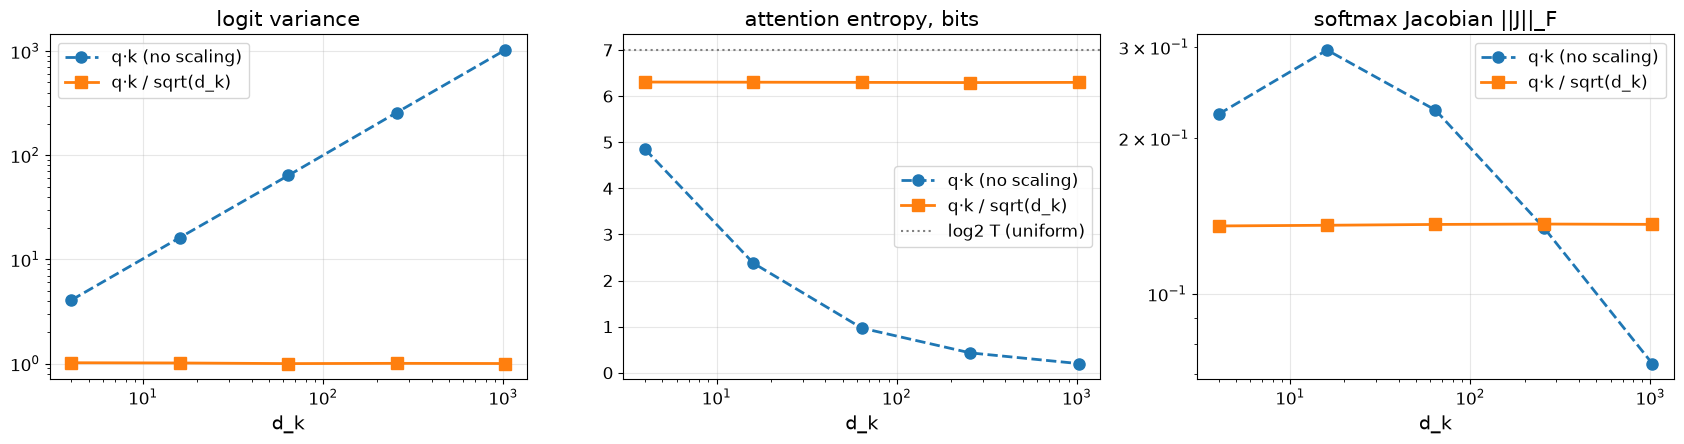

In [5]:
Tk, reps = 128, 2000
rows = []
for dk_ in [4, 16, 64, 256, 1024]:
    qv = torch.randn(reps, 1, dk_, generator=g); kv = torch.randn(reps, Tk, dk_, generator=g)
    logits = (qv @ kv.transpose(1, 2)).squeeze(1).double()
    for scaled in (False, True):
        s = logits / math.sqrt(dk_) if scaled else logits
        a = s.softmax(-1)
        ent = -(a * a.clamp_min(1e-30).log2()).sum(-1).mean().item()
        jfro = (((a ** 2).sum(-1) - 2 * (a ** 3).sum(-1) + ((a ** 2).sum(-1)) ** 2).clamp_min(0).sqrt()).mean().item()  # ||diag(a) - a a^T||_F
        rows.append(dict(dk=dk_, scaled=scaled, var=s.var().item(), maxa=a.max(-1).values.mean().item(), ent=ent, jfro=jfro))
print(f"{'d_k':>5} {'деление':>8} {'Var(логит)':>11} {'max a':>7} {'H(a), бит':>10} {'||J||_F':>9}")
for r in rows:
    print(f"{r['dk']:>5} {('да' if r['scaled'] else 'нет'):>8} {r['var']:>11.2f} {r['maxa']:>7.3f} {r['ent']:>10.3f} {r['jfro']:>9.4f}")
print(f"для сравнения: log2(T) = {math.log2(Tk):.3f} бит (равномерное внимание)")

fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))
for sc, st in [(False, "o--"), (True, "s-")]:
    rr = [r for r in rows if r["scaled"] == sc]; lab = "q·k / sqrt(d_k)" if sc else "q·k (no scaling)"
    axs[0].loglog([r["dk"] for r in rr], [r["var"] for r in rr], st, lw=2, ms=8, label=lab)
    axs[1].semilogx([r["dk"] for r in rr], [r["ent"] for r in rr], st, lw=2, ms=8, label=lab)
    axs[2].loglog([r["dk"] for r in rr], [r["jfro"] for r in rr], st, lw=2, ms=8, label=lab)
axs[1].axhline(math.log2(Tk), color="gray", ls=":", label="log2 T (uniform)")
for ax, t in zip(axs, ["logit variance", "attention entropy, bits", "softmax Jacobian ||J||_F"]):
    ax.set_title(t, fontsize=15); ax.set_xlabel("d_k", fontsize=14); ax.legend(fontsize=12); ax.tick_params(labelsize=12)
plt.tight_layout(); plt.show()

**Что видно.** Без деления дисперсия логита равна \(d_k\) (4,07; 16,2; 63,9; 257; 1024), с делением — 1,00 при любом \(d_k\). Без масштабирования внимание быстро становится почти one-hot: средний максимальный вес растёт с 0,22 до 0,94, а энтропия падает с 4,85 до 0,20 бита. С делением энтропия держится около 6,3 бита из возможных 7. Норма якобиана без деления меняется немонотонно. Сначала она растёт (0,30 при \(d_k = 16\)), пока распределение не стало слишком острым, а потом падает до 0,073 при \(d_k = 1024\). С делением она постоянна, около 0,136, при любом \(d_k\). Масштабирование не максимизирует градиент. Оно делает статистику логитов, а значит и поведение обучения, независимыми от размерности головы.

## 10. Перестановки и ядерная регрессия

### 10.1. Self-attention без позиций эквивариантен к перестановкам

Пусть \(P\) — матрица перестановки токенов. Для self-attention без маски и без позиционного кодирования \(\mathrm{SA}(PX) = P\,\mathrm{SA}(X)\) (раздел 5.1): слой не знает порядка. Причинная маска этот порядок вносит — на ней равенство нарушается. Проверим оба случая, а также среднее по позициям, которое без маски вообще не меняется.

In [6]:
d_ = 32; Tm = 12
Wq, Wk, Wv = (torch.randn(d_, d_, generator=g, dtype=torch.float64) / math.sqrt(d_) for _ in range(3))
def self_attn(X, mask=None):
    return attention(X @ Wq, X @ Wk, X @ Wv, mask)[0]
X = torch.randn(Tm, d_, generator=g, dtype=torch.float64)
perm = torch.randperm(Tm, generator=g)
print("перестановка:", perm.tolist())
for name, m in [("без маски", None), ("причинная маска", causal_mask(Tm))]:
    err = (self_attn(X[perm], m) - self_attn(X, m)[perm]).abs().max().item()
    pool = (self_attn(X[perm], m).mean(0) - self_attn(X, m).mean(0)).abs().max().item()
    print(f"{name:16s}: max |SA(PX) - P SA(X)| = {err:.2e}; изменение среднего по позициям = {pool:.2e}")

перестановка: [8, 6, 3, 7, 11, 2, 5, 9, 1, 0, 10, 4]
без маски       : max |SA(PX) - P SA(X)| = 4.44e-16; изменение среднего по позициям = 1.11e-16
причинная маска : max |SA(PX) - P SA(X)| = 3.09e+00; изменение среднего по позициям = 9.73e-01


**Что видно.** Без маски \(\mathrm{SA}(PX)\) и \(P\,\mathrm{SA}(X)\) совпадают до \(4\cdot 10^{-16}\), и среднее по позициям вообще не меняется. Без позиционной информации слой видит только мультимножество токенов. С причинной маской расхождение порядка единицы (3,09): маска сама вносит порядок, и поэтому декодер без позиций (NoPE) в принципе может учиться (раздел 5.6).

### 10.2. Attention как регрессия Надарая–Ватсона

Оценка Надарая–Ватсона с гауссовым ядром ширины \(h\):

\[
\hat f(x) = \sum_i \frac{\exp\!\big(-(x - x_i)^2/2h^2\big)}{\sum_j \exp\!\big(-(x - x_j)^2/2h^2\big)}\, y_i .
\]

Раскроем квадрат: \(-(x-x_i)^2/2h^2 = x x_i/h^2 - x_i^2/2h^2 - x^2/2h^2\). Последнее слагаемое одинаково для всех \(i\) и сокращается в softmax. Значит, это ровно dot-product attention с запросом \(q = (x, 1)/h\), ключами \(k_i = (x_i, -x_i^2/2)/h\) и значениями \(v_i = y_i\), без деления на \(\sqrt{d_k}\) (раздел 1.3). Проверим равенство численно и посмотрим, как ширина ядра, то есть «температура» внимания, управляет гладкостью.

h = 0.05: max |NW - attention| = 2.76e-13; MSE против sin(x) = 0.0721; средний max веса = 0.667
h = 0.30: max |NW - attention| = 7.77e-15; MSE против sin(x) = 0.0121; средний max веса = 0.156
h = 2.00: max |NW - attention| = 3.33e-16; MSE против sin(x) = 0.2108; средний max веса = 0.028


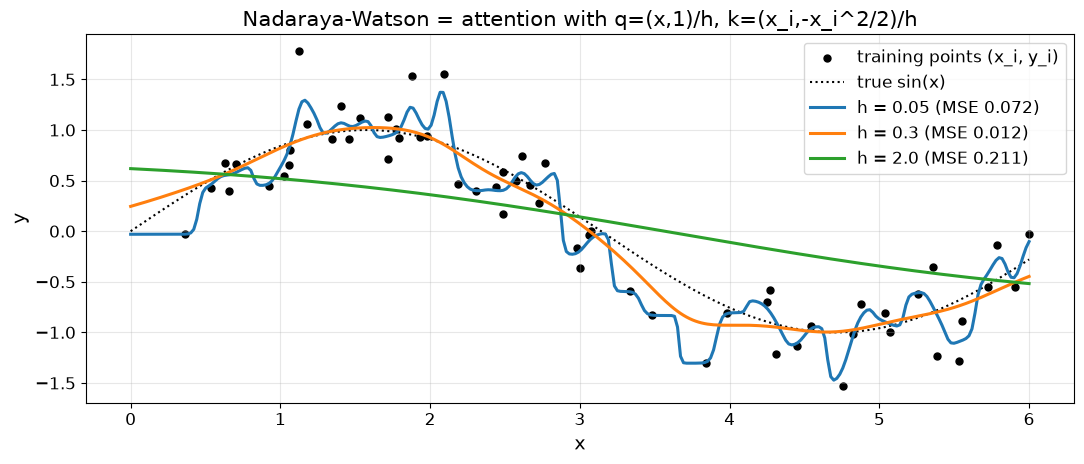

In [7]:
gx = torch.Generator().manual_seed(1)
xs = torch.sort(torch.rand(60, generator=gx, dtype=torch.float64) * 6).values
ys = torch.sin(xs) + 0.3 * torch.randn(60, generator=gx, dtype=torch.float64)
xq = torch.linspace(0, 6, 300, dtype=torch.float64)
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.scatter(xs, ys, s=25, c="k", label="training points (x_i, y_i)")
ax.plot(xq, torch.sin(xq), "k:", lw=1.5, label="true sin(x)")
for h in [0.05, 0.3, 2.0]:
    w = torch.softmax(-(xq[:, None] - xs[None, :]) ** 2 / (2 * h * h), dim=1)
    nw = w @ ys
    Q = torch.stack([xq, torch.ones_like(xq)], 1) / h
    K = torch.stack([xs, -xs ** 2 / 2], 1) / h
    att = torch.softmax(Q @ K.T, dim=1) @ ys
    mse = ((nw - torch.sin(xq)) ** 2).mean().item()
    print(f"h = {h:4.2f}: max |NW - attention| = {(nw - att).abs().max():.2e}; MSE против sin(x) = {mse:.4f}; "
          f"средний max веса = {w.max(1).values.mean():.3f}")
    ax.plot(xq, nw, lw=2.2, label=f"h = {h} (MSE {mse:.3f})")
ax.set_xlabel("x", fontsize=14); ax.set_ylabel("y", fontsize=14); ax.legend(fontsize=12)
ax.set_title("Nadaraya-Watson = attention with q=(x,1)/h, k=(x_i,-x_i^2/2)/h", fontsize=15)
plt.tight_layout(); plt.show()

**Что видно.** Оценка Надарая–Ватсона с гауссовым ядром совпадает с attention при \(q = (x, 1)/h\), \(k_i = (x_i, -x_i^2/2)/h\) до \(3\cdot 10^{-13}\): член \(-x^2/2h^2\) одинаков для всех ключей и сокращается в softmax. Ширина \(h\) играет роль обратной температуры. При \(h = 0{,}05\) средний максимальный вес 0,67: оценка почти копирует ближайшую точку и повторяет шум (MSE 0,072). При \(h = 2\) веса почти равномерны (0,028), оценка сглажена до почти прямой (MSE 0,211). Лучший результат даёт промежуточное \(h = 0{,}3\) (MSE 0,012).

## 11. Multi-head attention с нуля

Одна линейная проекция `qkv` даёт сразу \(Q, K, V\) размерности \(d\); они режутся на \(H\) голов по \(d_h = d/H\), каждая голова считает attention независимо, выходы склеиваются и проходят через \(W_O\) (раздел 3). Ниже тот же модуль, что используется в Mini-GPT, с опциональным RoPE (функция `apply_rope` определена в разделе 12; здесь он выключен).

Проверки:

1. совпадение с `nn.MultiheadAttention` при одинаковых весах;
2. причинность: изменение будущих токенов не меняет выход в прошлых позициях;
3. логит головы \(h\) равен билинейной форме \(x_i^\top W_{QK}^{h} x_j\), где \(W_{QK}^{h} = W_Q^{h} (W_K^{h})^\top/\sqrt{d_h}\) — матрица \(d\times d\) ранга не больше \(d_h\).

In [8]:
class MHA(nn.Module):
    def __init__(self, d, n_head, dropout=0.0):
        super().__init__()
        assert d % n_head == 0
        self.h, self.dh = n_head, d // n_head
        self.qkv = nn.Linear(d, 3 * d)
        self.proj = nn.Linear(d, d)
        self.dropout = dropout
    def forward(self, x, rope=None, causal=True, return_attn=False, cache=None):
        B, T, d = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.h, self.dh).permute(2, 0, 3, 1, 4)   # каждый (B, H, T, dh)
        if rope is not None:
            q, k = rope(q), rope(k)
        if cache is not None:                      # KV-кэш при генерации: дописываем новые ключи и значения
            if "k" in cache:
                k = torch.cat([cache["k"], k], 2); v = torch.cat([cache["v"], v], 2)
            cache["k"], cache["v"] = k, v
        if return_attn:
            Tk = k.shape[2]
            m = torch.ones(T, Tk, dtype=torch.bool, device=x.device).tril(Tk - T) if causal else None
            o, a = attention(q, k, v, m)
        else:
            is_causal = causal and T > 1 and (cache is None or k.shape[2] == T)
            o = F.scaled_dot_product_attention(q, k, v, is_causal=is_causal, dropout_p=self.dropout if self.training else 0.0)
            a = None
        o = o.transpose(1, 2).reshape(B, T, d)
        return (self.proj(o), a) if return_attn else self.proj(o)

torch.manual_seed(0)
d_, H_ = 64, 4
mha = MHA(d_, H_).double()
ref = nn.MultiheadAttention(d_, H_, batch_first=True).double()
with torch.no_grad():
    ref.in_proj_weight.copy_(mha.qkv.weight); ref.in_proj_bias.copy_(mha.qkv.bias)
    ref.out_proj.weight.copy_(mha.proj.weight); ref.out_proj.bias.copy_(mha.proj.bias)
X = torch.randn(2, 20, d_, dtype=torch.float64)
cm = ~causal_mask(20)                               # у nn.MultiheadAttention True означает «запрещено»
out_ref = ref(X, X, X, attn_mask=cm, need_weights=False)[0]
out_sdpa = mha(X); out_man, A = mha(X, return_attn=True)
print(f"ours (SDPA) vs nn.MultiheadAttention: {(out_sdpa - out_ref).abs().max():.2e}; ours (manual) vs SDPA: {(out_man - out_sdpa).abs().max():.2e}")

X2 = X.clone(); X2[:, 11:] = torch.randn(2, 9, d_, dtype=torch.float64)
dlt = (mha(X2) - mha(X)).abs().amax(dim=(0, 2))
print(f"причинность: max изменение выхода на позициях 0..10 = {dlt[:11].max():.1e}, на позициях 11..19 = {dlt[11:].min():.2f}..{dlt[11:].max():.2f}")

with torch.no_grad():
    Wq_, Wk_, _ = mha.qkv.weight.split(d_, 0)                     # (d, d) каждый: строки — выходные координаты
    h0 = slice(0, d_ // H_)
    Wqk = Wq_[h0].T @ Wk_[h0] / math.sqrt(d_ // H_)                # d x d
    bq, bk, _ = mha.qkv.bias.split(d_, 0)
    xi, xj = X[0, 7], X[0, 3]
    s_bil = (xi @ Wq_[h0].T + bq[h0]) @ (xj @ Wk_[h0].T + bk[h0]) / math.sqrt(d_ // H_)
    s_all = ((X[0] @ Wq_[h0].T + bq[h0]) @ (X[0] @ Wk_[h0].T + bk[h0]).T / math.sqrt(d_ // H_))
    print(f"логит головы 0 для (7, 3): из модуля {s_all[7, 3]:.6f}, билинейная форма {s_bil:.6f}; "
          f"без смещений x_i^T W_QK x_j = {xi @ Wqk @ xj:.6f}")
    sv = torch.linalg.svdvals(Wqk)
    print(f"W_QK головы 0: размер {tuple(Wqk.shape)}, ранг {torch.linalg.matrix_rank(Wqk).item()} (d_h = {d_ // H_}); "
          f"сингулярные числа 16-17: {sv[15]:.2e}, {sv[16]:.2e}")
    print("проверка весов: ln(a_73/a_70) =", f"{(A[0, 0, 7, 3] / A[0, 0, 7, 0]).log():.6f}", "= s_73 - s_70 =", f"{s_all[7, 3] - s_all[7, 0]:.6f}")

ours (SDPA) vs nn.MultiheadAttention: 0.00e+00; ours (manual) vs SDPA: 1.67e-16
причинность: max изменение выхода на позициях 0..10 = 0.0e+00, на позициях 11..19 = 0.16..0.26
логит головы 0 для (7, 3): из модуля -0.019852, билинейная форма -0.019852; без смещений x_i^T W_QK x_j = 0.011634
W_QK головы 0: размер (64, 64), ранг 16 (d_h = 16); сингулярные числа 16-17: 3.69e-02, 4.97e-17
проверка весов: ln(a_73/a_70) = -0.549904 = s_73 - s_70 = -0.549904


**Что видно.** Наш `MHA` с перенесёнными весами совпадает с `nn.MultiheadAttention` побитово, а ручной путь отличается от SDPA на \(2\cdot 10^{-16}\). Изменение токенов с 11-го по 19-й не меняет выход на позициях 0–10, а на поздних позициях выход меняется на 0,16–0,26: причинность соблюдается. Логит головы совпадает с билинейной формой \(x_i^\top W_{QK} x_j\) плюс члены от смещений. Матрица \(W_{QK}\) размера \(64\times 64\) имеет ранг ровно 16: 17-е сингулярное число \(5\cdot 10^{-17}\), то есть голова сравнивает токены только в 16-мерном подпространстве. Отношение весов \(\ln(a_{73}/a_{70})\) равно разности логитов, как и должно быть для softmax.

## 12. Позиционное кодирование и RoPE

### 12.1. Синусоидальное кодирование

\(\mathrm{PE}(m)_{2i} = \sin(m\theta_i)\), \(\mathrm{PE}(m)_{2i+1} = \cos(m\theta_i)\), \(\theta_i = 10000^{-2i/d}\) ([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)). Два свойства из раздела 5.2: скалярное произведение \(\mathrm{PE}(m)^\top \mathrm{PE}(n) = \sum_i \cos((m-n)\theta_i)\) зависит только от разности позиций; сдвиг на \(\Delta\) — линейное (блочно-ортогональное) преобразование \(\mathrm{PE}(m+\Delta) = M_\Delta\, \mathrm{PE}(m)\), не зависящее от \(m\).

PE(m)·PE(n) по диагоналям m - n = const: максимальный разброс 1.8e-13 (зависит только от m - n)
PE(m + 7) = M PE(m) для всех m: max ошибка 3.5e-14; M ортогональна: 2.2e-16


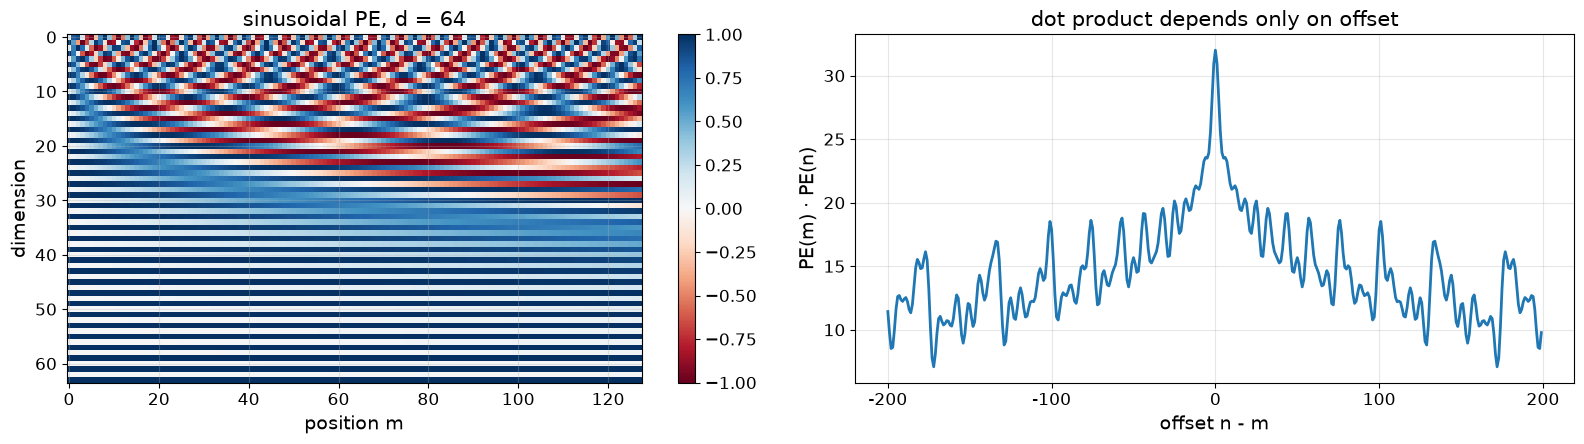

In [9]:
def sinusoidal(T, d, base=10000.0):
    pos = torch.arange(T, dtype=torch.float64)[:, None]
    th = base ** (-torch.arange(0, d, 2, dtype=torch.float64) / d)
    pe = torch.zeros(T, d, dtype=torch.float64)
    pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * th), torch.cos(pos * th)
    return pe, th

PE, TH = sinusoidal(512, 64)
G_ = PE @ PE.T
diag_spread = max((torch.diagonal(G_, off).max() - torch.diagonal(G_, off).min()).item() for off in range(0, 200))
print(f"PE(m)·PE(n) по диагоналям m - n = const: максимальный разброс {diag_spread:.1e} (зависит только от m - n)")
Dl = 7
M = torch.zeros(64, 64, dtype=torch.float64)
for i, t in enumerate(TH):
    c, s = math.cos(Dl * t), math.sin(Dl * t)
    M[2 * i:2 * i + 2, 2 * i:2 * i + 2] = torch.tensor([[c, s], [-s, c]], dtype=torch.float64)
print(f"PE(m + {Dl}) = M PE(m) для всех m: max ошибка {(PE[Dl:] - PE[:-Dl] @ M.T).abs().max():.1e}; M ортогональна: {(M @ M.T - torch.eye(64, dtype=torch.float64)).abs().max():.1e}")

fig, axs = plt.subplots(1, 2, figsize=(16, 4.6))
im = axs[0].imshow(PE[:128].T, aspect="auto", cmap="RdBu", vmin=-1, vmax=1)
axs[0].set_xlabel("position m", fontsize=14); axs[0].set_ylabel("dimension", fontsize=14); axs[0].set_title("sinusoidal PE, d = 64", fontsize=15)
plt.colorbar(im, ax=axs[0])
axs[1].plot(G_[256, 256 - 200:256 + 200].numpy(), lw=2)
axs[1].set_xticks([0, 100, 200, 300, 400], ["-200", "-100", "0", "100", "200"])
axs[1].set_xlabel("offset n - m", fontsize=14); axs[1].set_ylabel("PE(m) · PE(n)", fontsize=14)
axs[1].set_title("dot product depends only on offset", fontsize=15)
plt.tight_layout(); plt.show()

**Что видно.** Скалярное произведение синусоидальных кодов зависит только от \(n - m\): разброс вдоль диагоналей \(1{,}8\cdot 10^{-13}\). Сдвиг на 7 позиций действительно линейный: \(\mathrm{PE}(m + 7) = M\,\mathrm{PE}(m)\) с ортогональной блочно-диагональной \(M\) и ошибкой \(3{,}5\cdot 10^{-14}\) — это гипотеза Vaswani et al. На тепловой карте первые измерения колеблются быстро, а последние почти постоянны на 128 позициях. Профиль справа симметричен и максимален (\(d/2 = 32\)) при нулевом сдвиге, но спадает не монотонно, с многочисленными побочными пиками.

### 12.2. RoPE

RoPE поворачивает каждую пару координат \((2i, 2i+1)\) запроса и ключа на угол \(m\theta_i\), где \(m\) — позиция ([Su et al., 2021](https://arxiv.org/abs/2104.09864)). Реализация через комплексные числа: пара — это \(z = x_{2i} + \mathrm{i}\,x_{2i+1}\), поворот — умножение на \(e^{\mathrm{i} m\theta_i}\). Параметр `scale` нужен для Position Interpolation (раздел 5.5): позиции делятся на `scale`.

Проверяем раздел 5.3: \(\langle R_m q, R_n k\rangle\) зависит только от \(n - m\), а поворот сохраняет норму.

In [10]:
def rope_angles(T, dh, base=10000.0, scale=1.0, offset=0, device=None):
    th = base ** (-torch.arange(0, dh, 2, dtype=torch.float64, device=device) / dh)
    pos = (torch.arange(offset, offset + T, dtype=torch.float64, device=device) / scale)[:, None]
    return torch.polar(torch.ones(T, dh // 2, dtype=torch.float64, device=device), pos * th)   # e^{i m theta}, (T, dh/2)

def apply_rope(x, rot):
    """x: (..., T, dh), rot: (T, dh/2) комплексные множители."""
    xc = torch.view_as_complex(x.double().reshape(*x.shape[:-1], -1, 2).contiguous())
    return torch.view_as_real(xc * rot).reshape(x.shape).to(x.dtype)

dh = 64
rot = rope_angles(300, dh)
qv = torch.randn(dh, generator=g, dtype=torch.float64); kv = torch.randn(dh, generator=g, dtype=torch.float64)
Rq = apply_rope(qv.expand(300, dh), rot); Rk = apply_rope(kv.expand(300, dh), rot)
pairs = [(0, 5), (37, 42), (250, 255), (3, 0), (120, 117)]
print("<R_m q, R_n k> для пар с одинаковой разностью n - m:")
for m, n in pairs:
    print(f"  m={m:3d}, n={n:3d}, n-m={n - m:+d}: {Rq[m] @ Rk[n]:+.10f}")
S_ = Rq @ Rk.T
spread = max((torch.diagonal(S_, off).max() - torch.diagonal(S_, off).min()).item() for off in range(-100, 101))
print(f"максимальный разброс вдоль диагоналей n - m = const: {spread:.1e}; изменение нормы при повороте: {(Rq.norm(dim=1) - qv.norm()).abs().max():.1e}")

<R_m q, R_n k> для пар с одинаковой разностью n - m:
  m=  0, n=  5, n-m=+5: +3.6126740228
  m= 37, n= 42, n-m=+5: +3.6126740228
  m=250, n=255, n-m=+5: +3.6126740228
  m=  3, n=  0, n-m=-3: -0.6980351930
  m=120, n=117, n-m=-3: -0.6980351930
максимальный разброс вдоль диагоналей n - m = const: 1.1e-13; изменение нормы при повороте: 8.9e-16


**Что видно.** Для пар позиций с одинаковой разностью \(n - m\) логиты RoPE совпадают до десятого знака — и для \(n - m = +5\), и для \(-3\) — при любой абсолютной позиции. Максимальный разброс вдоль диагоналей \(1{,}1\cdot 10^{-13}\). Поворот не меняет норму векторов (\(9\cdot 10^{-16}\)): RoPE сохраняет длины и меняет только углы.

### 12.3. Затухание с расстоянием

В [RoFormer](https://arxiv.org/abs/2104.09864) показано, что при \(q = k\) с одинаковыми компонентами скалярное произведение \(\langle R_m q, R_n k\rangle \propto \sum_i \cos((n-m)\theta_i)\) в среднем убывает с ростом \(|n-m|\), и выведена верхняя оценка через частичные суммы \(\frac{1}{d/2}\sum_j |\sum_{i<j} e^{\mathrm{i}(n-m)\theta_i}|\) (на графике она нормирована на значение при нулевом расстоянии). Для случайных \(q, k\) математическое ожидание логита равно нулю на любом расстоянии, затухание касается лишь «согласованной» части. Построим обе кривые и посмотрим, как разные пары частот вносят вклад: высокие частоты быстро осциллируют, низкие почти не меняются на всём контексте.

q = k = 1: нормированный логит на расстоянии 0 / 10 / 100 / 1000: 1.000 / 0.658 / 0.559 / 0.279
оценка RoFormer на тех же расстояниях: 1.000 / 0.534 / 0.452 / 0.248
случайные q, k: средний логит / d по расстояниям, max |.| = 0.0046


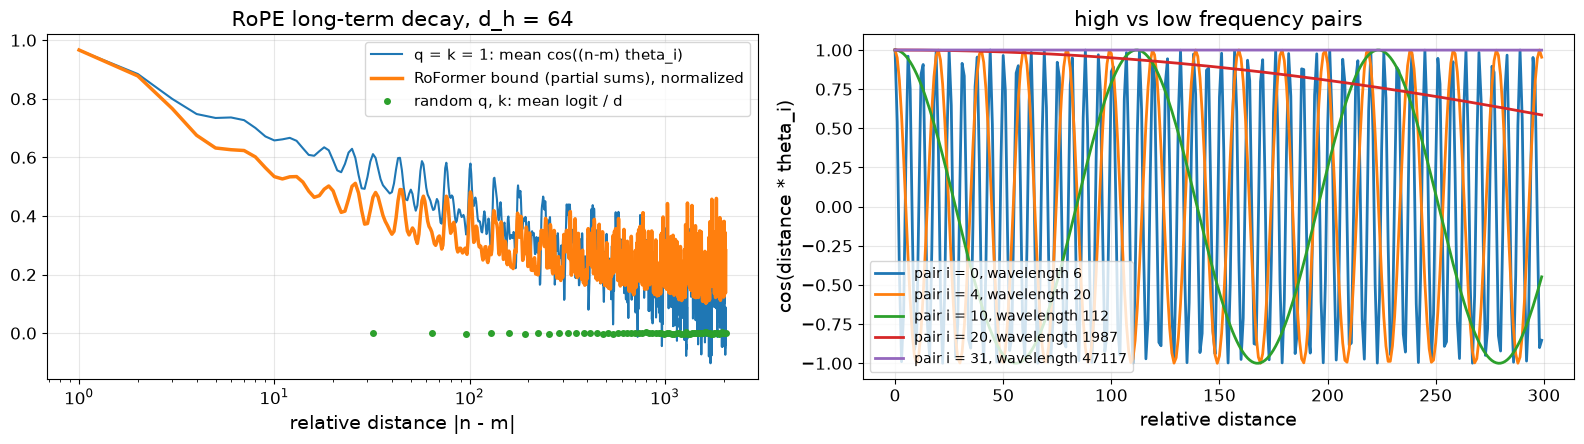

In [11]:
dist = np.arange(0, 2049)
th = 10000.0 ** (-np.arange(0, dh, 2) / dh)
cos_sum = np.cos(dist[:, None] * th[None, :]).sum(1) / (dh // 2)
ps = np.cumsum(np.exp(1j * dist[:, None] * th[None, :]), axis=1)
bound = np.abs(ps).mean(1); bound = bound / bound[0]          # нормируем на значение при нулевом расстоянии
rnd = []
for dd in dist[::32]:
    qq_ = torch.randn(4000, dh, dtype=torch.float64, generator=g); kk_ = torch.randn(4000, dh, dtype=torch.float64, generator=g)
    rr = rope_angles(1, dh, offset=int(dd))
    rnd.append((apply_rope(qq_[:, None], rope_angles(1, dh))[:, 0] * apply_rope(kk_[:, None], rr)[:, 0]).sum(1).mean().item() / dh)
print(f"q = k = 1: нормированный логит на расстоянии 0 / 10 / 100 / 1000: {cos_sum[0]:.3f} / {cos_sum[10]:.3f} / {cos_sum[100]:.3f} / {cos_sum[1000]:.3f}")
print(f"оценка RoFormer на тех же расстояниях: {bound[0]:.3f} / {bound[10]:.3f} / {bound[100]:.3f} / {bound[1000]:.3f}")
print(f"случайные q, k: средний логит / d по расстояниям, max |.| = {np.abs(rnd).max():.4f}")

fig, axs = plt.subplots(1, 2, figsize=(16, 4.6))
axs[0].semilogx(dist[1:], cos_sum[1:], lw=1.5, label="q = k = 1: mean cos((n-m) theta_i)")
axs[0].semilogx(dist[1:], bound[1:], lw=2.5, label="RoFormer bound (partial sums), normalized")
axs[0].semilogx(dist[::32][1:], rnd[1:], "o", ms=4, label="random q, k: mean logit / d")
axs[0].set_xlabel("relative distance |n - m|", fontsize=14); axs[0].legend(fontsize=11); axs[0].set_title("RoPE long-term decay, d_h = 64", fontsize=15)
for i in [0, 4, 10, 20, 31]:
    axs[1].plot(dist[:300], np.cos(dist[:300] * th[i]), lw=2, label=f"pair i = {i}, wavelength {2 * np.pi / th[i]:.0f}")
axs[1].set_xlabel("relative distance", fontsize=14); axs[1].set_ylabel("cos(distance * theta_i)", fontsize=14)
axs[1].legend(fontsize=10, loc="lower left"); axs[1].set_title("high vs low frequency pairs", fontsize=15)
plt.tight_layout(); plt.show()

**Что видно.** При \(q = k = \mathbf{1}\) нормированный логит убывает с расстоянием: 1,000 / 0,658 / 0,559 / 0,279 на расстояниях 0 / 10 / 100 / 1000, и оценка RoFormer через частичные суммы идёт ниже его с тем же порядком (1,000 / 0,534 / 0,452 / 0,248). Затухание не монотонно, кривые сильно осциллируют. Для случайных \(q, k\) средний логит около нуля (не больше 0,005) на любом расстоянии. Затухание — свойство согласованных \(q\) и \(k\), а не закон, который навязывается любой голове. На правой панели видно, что пара 0 (длина волны 6 токенов) различает соседние позиции, а пара 31 (47 117 токенов) на расстоянии 300 почти не поворачивается.

### 12.4. Как растянуть контекст: PI и NTK-aware

Модель обучена на позициях \(0..L-1\); хотим применять её к длине \(sL\). Position Interpolation ([Chen et al., 2023](https://arxiv.org/abs/2306.15595)) делит позиции на \(s\): все углы попадают в обученный диапазон, но и высокие частоты сжимаются в \(s\) раз, соседние токены становятся хуже различимы. NTK-aware масштабирование (раздел 5.5, обсуждается в [YaRN](https://arxiv.org/abs/2309.00071)) меняет основание \(b \to b\, s^{d/(d-2)}\): самая высокая частота не меняется, самая низкая уменьшается ровно в \(s\) раз. Сравним множитель, на который уменьшается частота каждой пары.

s = 4.0: уменьшение частоты пары 0 / 16 / 31:  PI 4.00 / 4.00 / 4.00;  NTK 1.00 / 2.05 / 4.00


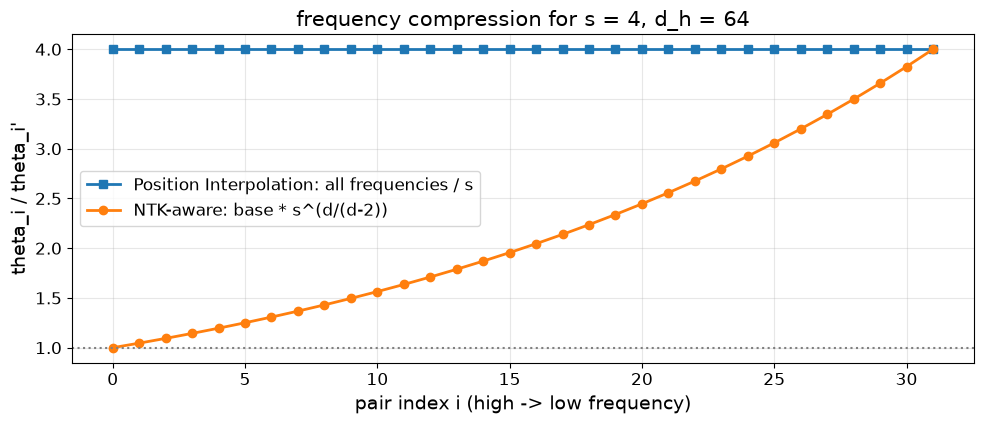

In [12]:
s_ext = 4.0
th_pi = th / s_ext
th_ntk = (10000.0 * s_ext ** (dh / (dh - 2))) ** (-np.arange(0, dh, 2) / dh)
print(f"s = {s_ext}: уменьшение частоты пары 0 / 16 / 31:  PI {th[0] / th_pi[0]:.2f} / {th[16] / th_pi[16]:.2f} / {th[31] / th_pi[31]:.2f};  "
      f"NTK {th[0] / th_ntk[0]:.2f} / {th[16] / th_ntk[16]:.2f} / {th[31] / th_ntk[31]:.2f}")
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(th / th_pi, "s-", lw=2, label="Position Interpolation: all frequencies / s")
ax.plot(th / th_ntk, "o-", lw=2, label="NTK-aware: base * s^(d/(d-2))")
ax.axhline(1, color="gray", ls=":")
ax.set_xlabel("pair index i (high -> low frequency)", fontsize=14); ax.set_ylabel("theta_i / theta_i'", fontsize=14)
ax.set_title(f"frequency compression for s = {s_ext:.0f}, d_h = {dh}", fontsize=15); ax.legend(fontsize=12)
plt.tight_layout(); plt.show()

**Что видно.** При \(s = 4\) Position Interpolation уменьшает все частоты в 4 раза, в том числе самые высокие, которые отвечают за различение соседних токенов. NTK-aware масштабирование основания почти не трогает высокие частоты (пара 0: 1,00; пара 16: 2,05) и уменьшает в 4 раза только самую низкую (пара 31). В разделе 15.2 видно, к чему это приводит без дообучения.

## 13. Mini-GPT

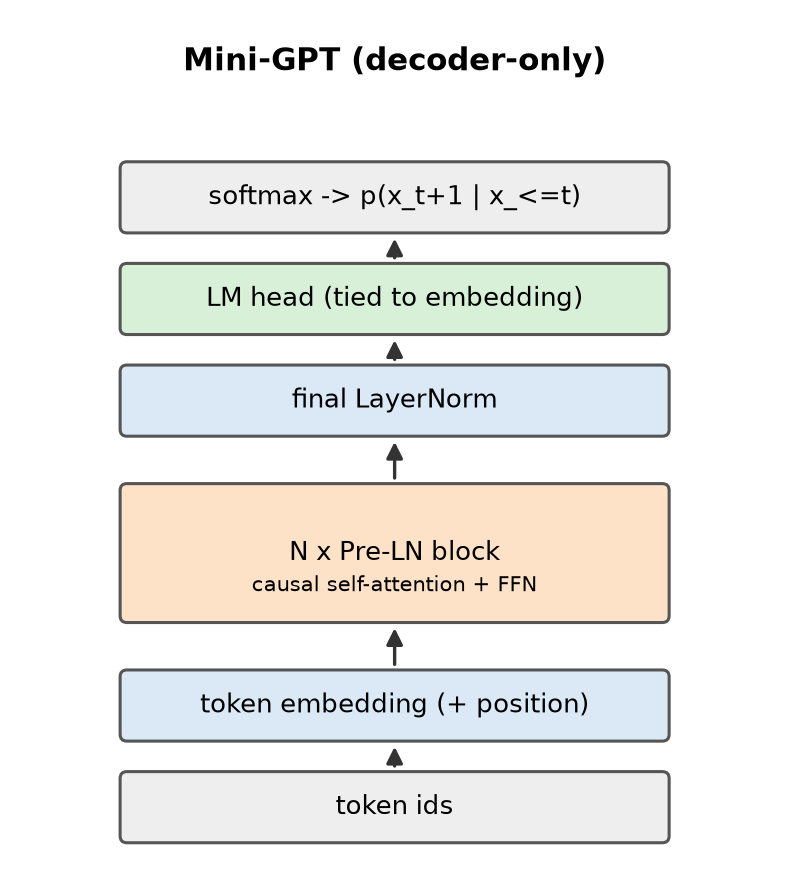

Декодер в стиле GPT-2 и [nanoGPT](https://github.com/karpathy/nanoGPT): эмбеддинг токенов, \(L\) блоков, финальный LayerNorm, выходной слой со связанными весами (weight tying, [Press & Wolf, 2017](https://arxiv.org/abs/1608.05859)). Блок — причинный MHA из раздела 11 и FFN \(d \to 4d \to d\) с GELU. Варианты:

- `pos`: `"rope"` — поворот \(q, k\) в каждом слое; `"learned"` — обучаемая таблица позиций, прибавляется к эмбеддингу; `"sin"` — синусоидальная таблица; `"nope"` — никаких позиций, порядок модель узнаёт только через причинную маску ([Haviv et al., 2022](https://arxiv.org/abs/2203.16634));
- `norm`: `"pre"` — \(x + f(\mathrm{LN}(x))\); `"post"` — \(\mathrm{LN}(x + f(x))\), как в исходном трансформере (раздел 4.1);
- `rope_scale`: делитель позиций для Position Interpolation при выводе.

In [13]:
class Block(nn.Module):
    def __init__(self, d, n_head, norm="pre", dropout=0.0):
        super().__init__()
        self.norm = norm
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = MHA(d, n_head, dropout)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d), nn.Dropout(dropout))
        self.drop = nn.Dropout(dropout)
    def forward(self, x, rope=None, return_attn=False, cache=None):
        if self.norm == "pre":
            r = self.attn(self.ln1(x), rope, return_attn=return_attn, cache=cache)
            a, r = (r[1], r[0]) if return_attn else (None, r)
            x = x + self.drop(r)
            x = x + self.mlp(self.ln2(x))
        else:
            r = self.attn(x, rope, return_attn=return_attn, cache=cache)
            a, r = (r[1], r[0]) if return_attn else (None, r)
            x = self.ln1(x + self.drop(r))
            x = self.ln2(x + self.mlp(x))
        return (x, a) if return_attn else x

class GPT(nn.Module):
    def __init__(self, V, d, n_layer, n_head, ctx, pos="rope", norm="pre", dropout=0.0, rope_base=10000.0):
        super().__init__()
        self.pos, self.ctx, self.dh, self.rope_base, self.rope_scale = pos, ctx, d // n_head, rope_base, 1.0
        self.tok = nn.Embedding(V, d)
        if pos == "learned":
            self.wpe = nn.Embedding(ctx, d)
        if pos == "sin":
            self.register_buffer("wpe_sin", sinusoidal(4 * ctx, d)[0].float(), persistent=False)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([Block(d, n_head, norm, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(d) if norm == "pre" else nn.Identity()
        self.head = nn.Linear(d, V, bias=False)
        self.head.weight = self.tok.weight                       # weight tying
        self.apply(self._init)
        for n_, p in self.named_parameters():                     # масштаб выходных проекций, как в GPT-2
            if n_.endswith("proj.weight") or n_.endswith("mlp.2.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * n_layer))
    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, 0.0, 0.02)
            if m.bias is not None: nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, 0.0, 0.02)
    def forward(self, idx, targets=None, return_attn=False, caches=None, offset=0):
        B, T = idx.shape
        x = self.tok(idx)
        if self.pos == "learned":
            x = x + self.wpe(torch.arange(offset, offset + T, device=idx.device))
        if self.pos == "sin":
            x = x + self.wpe_sin[offset:offset + T]
        rope = None
        if self.pos == "rope":
            rot = rope_angles(T, self.dh, self.rope_base, self.rope_scale, offset, idx.device)
            rope = lambda t: apply_rope(t, rot)
        x = self.drop(x)
        attns = []
        for i, blk in enumerate(self.blocks):
            c = None if caches is None else caches[i]
            if return_attn:
                x, a = blk(x, rope, True, c); attns.append(a)
            else:
                x = blk(x, rope, False, c)
        logits = self.head(self.ln_f(x))
        loss = None if targets is None else F.cross_entropy(logits.reshape(-1, logits.shape[-1]), targets.reshape(-1))
        return (logits, loss, attns) if return_attn else (logits, loss)

def make_gpt(pos="rope", norm="pre", **kw):
    cfg = dict(V=NV, d=S["d"], n_layer=S["n_layer"], n_head=S["n_head"], ctx=S["ctx"], pos=pos, norm=norm, dropout=S["dropout"], rope_base=S["rope_base"])
    cfg.update(kw)
    return GPT(**cfg).to(DEVICE)

### 13.1. Параметры и FLOPs

Раздел 4.5: блок содержит \(4d^2 + 4d\) параметров внимания (\(W_Q, W_K, W_V, W_O\) со смещениями), \(8d^2 + 5d\) в FFN и \(4d\) в двух LayerNorm, итого \(12d^2 + 13d\). Плюс таблица токенов \(Vd\) (она же выходной слой), таблица позиций \(L_{\mathrm{ctx}} d\) для learned и \(2d\) финального LayerNorm.

Прямой проход на последовательности длины \(T\) стоит \(2 N_{\mathrm{mm}} T\) FLOPs на матричные умножения с весами (\(N_{\mathrm{mm}}\) — число весов в этих умножениях, включая выходной слой) плюс \(4 n_{\mathrm{layer}} T^2 d\) на \(QK^\top\) и \(AV\). Сверим формулу с прямым подсчётом через `torch.utils.flop_counter`.

In [14]:
from torch.utils.flop_counter import FlopCounterMode
def n_params(m): return sum(p.numel() for p in m.parameters())
d, L_, Tc = S["d"], S["n_layer"], S["ctx"]
for pos in ["rope", "learned", "nope"]:
    m = make_gpt(pos)
    formula = L_ * (12 * d * d + 13 * d) + NV * d + 2 * d + (Tc * d if pos == "learned" else 0)
    print(f"pos={pos:8s}: параметров {n_params(m):,}, по формуле {formula:,}; в блоках {L_ * (12 * d * d + 13 * d):,}, из них 12 L d^2 = {L_ * 12 * d * d:,} ({L_ * 12 * d * d / n_params(m):.1%} всех параметров)")
m = make_gpt("nope").eval()
N_mm = L_ * 12 * d * d + NV * d
with FlopCounterMode(display=False) as fc, torch.no_grad():
    m(torch.zeros(1, Tc, dtype=torch.long, device=DEVICE), return_attn=True)   # ручной attention: его матмулы видны счётчику
fl_meas = fc.get_total_flops()
fl_form = 2 * N_mm * Tc + 4 * L_ * Tc * Tc * d
print(f"\nпрямой проход, T = {Tc}: измерено {fl_meas / 1e6:.1f} MFLOPs, формула 2 N_mm T + 4 L T^2 d = {fl_form / 1e6:.1f} MFLOPs")
print(f"доля attention-слагаемого 4 L T^2 d: {4 * L_ * Tc * Tc * d / fl_form:.1%} (оценка T / (6 d) = {Tc / (6 * d):.1%} без выходного слоя)")
print(f"обучение (прямой + обратный ~ 3x прямого) на шаг из {S['bs']} x {Tc} токенов: ~{3 * fl_form * S['bs'] / 1e9:.1f} GFLOPs")
del m

pos=rope    : параметров 801,664, по формуле 801,664; в блоках 793,088, из них 12 L d^2 = 786,432 (98.1% всех параметров)
pos=learned : параметров 818,048, по формуле 818,048; в блоках 793,088, из них 12 L d^2 = 786,432 (96.1% всех параметров)
pos=nope    : параметров 801,664, по формуле 801,664; в блоках 793,088, из них 12 L d^2 = 786,432 (98.1% всех параметров)



прямой проход, T = 128: измерено 237.0 MFLOPs, формула 2 N_mm T + 4 L T^2 d = 237.0 MFLOPs
доля attention-слагаемого 4 L T^2 d: 14.2% (оценка T / (6 d) = 16.7% без выходного слоя)
обучение (прямой + обратный ~ 3x прямого) на шаг из 32 x 128 токенов: ~22.8 GFLOPs


**Что видно.** Число параметров совпадает с формулой для всех вариантов: 801 664 для RoPE и NoPE, на \(128\cdot 128 = 16\,384\) больше для обучаемых позиций. Слагаемое \(12Ld^2\) составляет 98 % параметров: при символьном словаре из 65 знаков эмбеддинги почти ничего не весят. Счётчик FLOPs PyTorch даёт за прямой проход ровно 237,0 MFLOPs, как и формула \(2N_{\text{mm}}T + 4LT^2d\). Доля attention-слагаемого 14,2 % (оценка \(T/6d\) без выходного слоя — 16,7 %). Шаг обучения стоит около 22,8 GFLOPs.

## 14. Обучение Mini-GPT

Все варианты обучаются одинаково: AdamW, линейный прогрев `warmup` шагов, затем косинусное убывание до нуля, weight decay 0,1 для матриц, клиппинг нормы градиента 1, случайные фрагменты длины `ctx`. Сид и порядок батчей одинаковые. Варианты: RoPE, обучаемые позиции и NoPE с Pre-LN, а также RoPE с Post-LN.

Валидационный bpc считаем скользящим окном: окно длины `ctx` сдвигается на `ctx/2`, учитываются только предсказания во второй половине окна. Так каждый символ валидации предсказывается по контексту не короче `ctx/2`. LSTM в лекции 1 переносила скрытое состояние через весь валидационный текст, то есть формально видела более длинный контекст.

In [15]:
def get_batch(ids, bs, T, gen):
    ix = torch.randint(0, len(ids) - T - 1, (bs,), generator=gen)
    x = torch.stack([ids[i:i + T] for i in ix]); y = torch.stack([ids[i + 1:i + T + 1] for i in ix])
    return x.to(DEVICE), y.to(DEVICE)

@torch.no_grad()
def eval_bpc(model, ids, ctx=None, max_windows=None):
    model.eval(); ctx = ctx or S["ctx"]; half = ctx // 2
    starts = list(range(0, len(ids) - ctx - 1, half))
    if max_windows: starts = starts[::max(1, len(starts) // max_windows)]
    nll, n = 0.0, 0
    for b in range(0, len(starts), 64):
        st = starts[b:b + 64]
        x = torch.stack([ids[s:s + ctx] for s in st]).to(DEVICE); y = torch.stack([ids[s + 1:s + ctx + 1] for s in st]).to(DEVICE)
        logits = model(x)[0].float()
        lp = F.cross_entropy(logits.reshape(-1, NV), y.reshape(-1), reduction="none").view(len(st), ctx)
        first = [0 if s == 0 else half for s in st]
        for r, f0 in enumerate(first):
            nll += lp[r, f0:].sum().item(); n += ctx - f0
    model.train()
    return nll / n / math.log(2)

def train_gpt(pos="rope", norm="pre", steps=S["steps"], lr=S["lr"], warmup=S["warmup"], n_val=5, seed=SEED):
    torch.manual_seed(seed); gen = torch.Generator().manual_seed(seed)
    model = make_gpt(pos, norm)
    decay = [p for n_, p in model.named_parameters() if p.dim() >= 2]
    no_decay = [p for n_, p in model.named_parameters() if p.dim() < 2]
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": S["wd"]}, {"params": no_decay, "weight_decay": 0.0}], lr=lr, betas=(0.9, 0.95))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda i: min(1.0, (i + 1) / warmup) * 0.5 * (1 + math.cos(math.pi * min(i, steps) / steps)))
    log = dict(step=[], loss=[], gnorm=[], val=[])
    t0 = time.time()
    for it in range(1, steps + 1):
        x, y = get_batch(TR, S["bs"], S["ctx"], gen)
        loss = model(x, y)[1]
        opt.zero_grad(set_to_none=True); loss.backward()
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), S["clip"]).item()
        opt.step(); sched.step()
        log["step"].append(it); log["loss"].append(loss.item() / math.log(2)); log["gnorm"].append(gn)
        if it % (steps // n_val) == 0 or it == steps:
            log["val"].append((it, eval_bpc(model, VA, max_windows=None if it == steps else 400)))
    log["time"] = time.time() - t0
    return model, log

RUNS = {}
for pos, norm in [("rope", "pre"), ("learned", "pre"), ("nope", "pre"), ("rope", "post")]:
    name = f"{pos}/{norm}-LN"
    model, log = train_gpt(pos, norm)
    RUNS[name] = dict(model=model, log=log, params=n_params(model))
    print(f"{name:16s}: {log['time']:5.0f} с, {n_params(model):,} параметров | val bpc по ходу: "
          + ", ".join(f"{v:.3f}" for _, v in log["val"]) + f" | норма градиента: медиана {np.median(log['gnorm']):.2f}, максимум {max(log['gnorm']):.1f}")

rope/pre-LN     :   515 с, 801,664 параметров | val bpc по ходу: 2.527, 2.303, 2.187, 2.141, 2.124 | норма градиента: медиана 0.58, максимум 6.6


learned/pre-LN  :   453 с, 818,048 параметров | val bpc по ходу: 2.790, 2.472, 2.289, 2.222, 2.194 | норма градиента: медиана 0.75, максимум 5.5


nope/pre-LN     :   457 с, 801,664 параметров | val bpc по ходу: 3.122, 2.650, 2.434, 2.339, 2.300 | норма градиента: медиана 0.95, максимум 6.6


rope/post-LN    :   515 с, 801,408 параметров | val bpc по ходу: 2.617, 2.387, 2.261, 2.214, 2.196 | норма градиента: медиана 0.50, максимум 3.3


**Что видно.** Все четыре варианта обучились без расхождений, по 450–515 с на вариант. Лучший вариант — RoPE с Pre-LN, 2,124 бита на символ. Обучаемые позиции дают 2,194, Post-LN с тем же RoPE — 2,196, NoPE — 2,300. NoPE учится заметно медленнее (3,12 против 2,53 на первой оценке), но всё же учится: порядок модель восстанавливает только через причинную маску. Post-LN при 4 слоях и прогреве в 100 шагов стабилен и в конце почти догоняет Pre-LN, хотя первые оценки хуже (2,617 против 2,527). Пики нормы градиента 3,3–6,6 срезаются клиппингом до 1.

Промежуточные значения bpc посчитаны по 400 окнам валидации, последнее — по всей валидации.

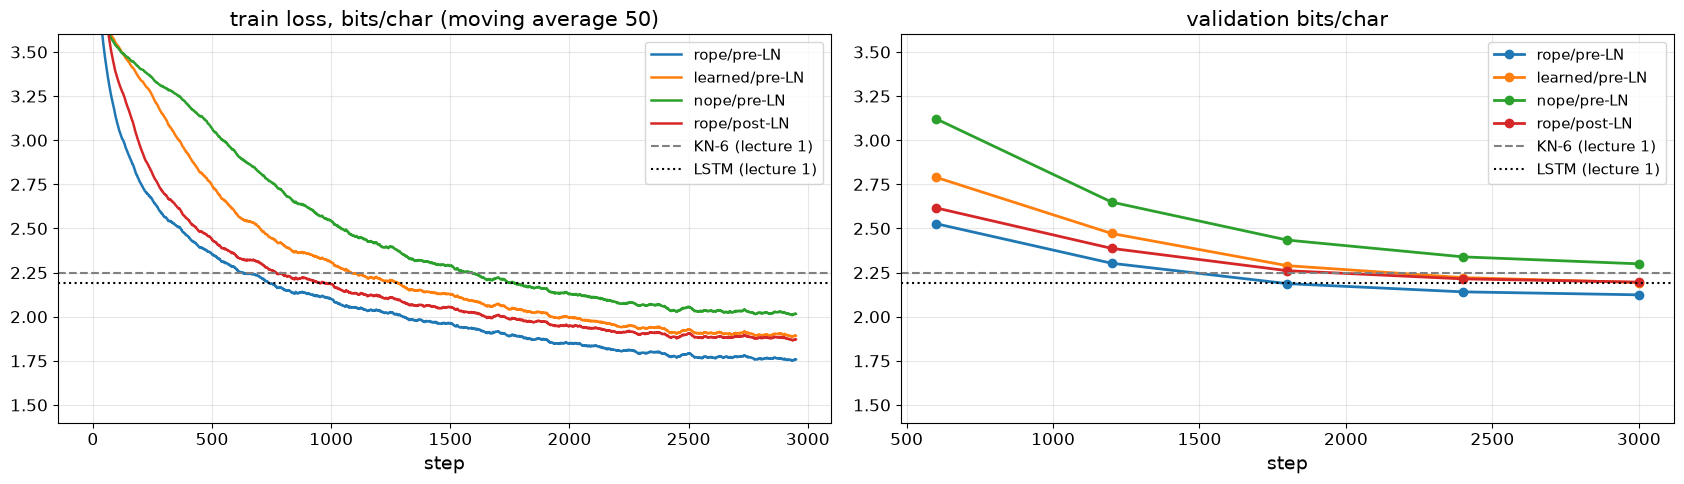

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(17, 5))
sm = lambda v, w=50: np.convolve(v, np.ones(w) / w, mode="valid")
for name, r in RUNS.items():
    axs[0].plot(sm(r["log"]["loss"]), lw=1.8, label=name)
    st, vv = zip(*r["log"]["val"]); axs[1].plot(st, vv, "o-", lw=2, ms=6, label=name)
for ax in axs:
    ax.axhline(L1_REF["Kneser–Ney, n = 6"], color="gray", ls="--", label="KN-6 (lecture 1)")
    ax.axhline(L1_REF["LSTM, 351 тыс. параметров"], color="k", ls=":", label="LSTM (lecture 1)")
    ax.set_xlabel("step", fontsize=14); ax.set_ylim(1.4, 3.6); ax.legend(fontsize=11); ax.tick_params(labelsize=12)
axs[0].set_title("train loss, bits/char (moving average 50)", fontsize=15); axs[1].set_title("validation bits/char", fontsize=15)
plt.tight_layout(); plt.show()

**Что видно.** На валидации RoPE/Pre-LN обгоняет KN-6 лекции 1 (2,248) между шагами 1200 и 1800, а LSTM (2,193) — к шагу 1800 (2,187). Обучаемые позиции и Post-LN доходят до уровня LSTM только к концу. NoPE остаётся хуже KN-6. Потеря на обучении к концу около 1,75 бита у лучшей модели, на 0,35–0,4 бита ниже валидации. За 12 эпох без dropout модель начинает запоминать корпус, поэтому на GPU-ветке включён dropout 0,2. Mini-GPT выигрывает у LSTM немного (0,07 бита) при вдвое большем числе параметров. На коротком CPU-бюджете преимущество трансформера скромное.

### 14.1. Residual stream в Pre-LN и Post-LN

Раздел 4.1 предсказывает разное поведение двух схем. В Pre-LN residual stream не нормализуется: его норма может расти от блока к блоку, а градиент потери по \(x_l\) приходит в каждый блок по тождественному пути. В Post-LN после каждого блока стоит LayerNorm, норма \(x_l\) фиксирована на уровне \(\approx\sqrt{d}\cdot|\gamma|\), а градиент проходит через якобианы всех последующих LayerNorm. Измерим среднюю по токенам норму \(\|x_l\|\) на выходе каждого блока и норму \(\|\partial\mathcal{L}/\partial x_l\|\) (умноженную на число токенов в батче, чтобы не зависеть от усреднения потери) — до обучения и после.

rope/pre-LN   init    | ||x_l||:   0.22   0.32   0.39   0.45   0.51 | ||dL/dx_l||:  11.45   7.69   6.24   5.47   4.89
rope/pre-LN   trained | ||x_l||:   1.03   7.26   9.56  11.28  16.64 | ||dL/dx_l||:   9.78   1.67   1.31   0.99   0.57
rope/post-LN  init    | ||x_l||:   0.22  11.31  11.31  11.31  11.31 | ||dL/dx_l||:  10.98   0.21   0.21   0.21   0.22
rope/post-LN  trained | ||x_l||:   1.00  11.53  11.83  11.83  17.18 | ||dL/dx_l||:   7.49   0.91   1.03   1.07   0.60


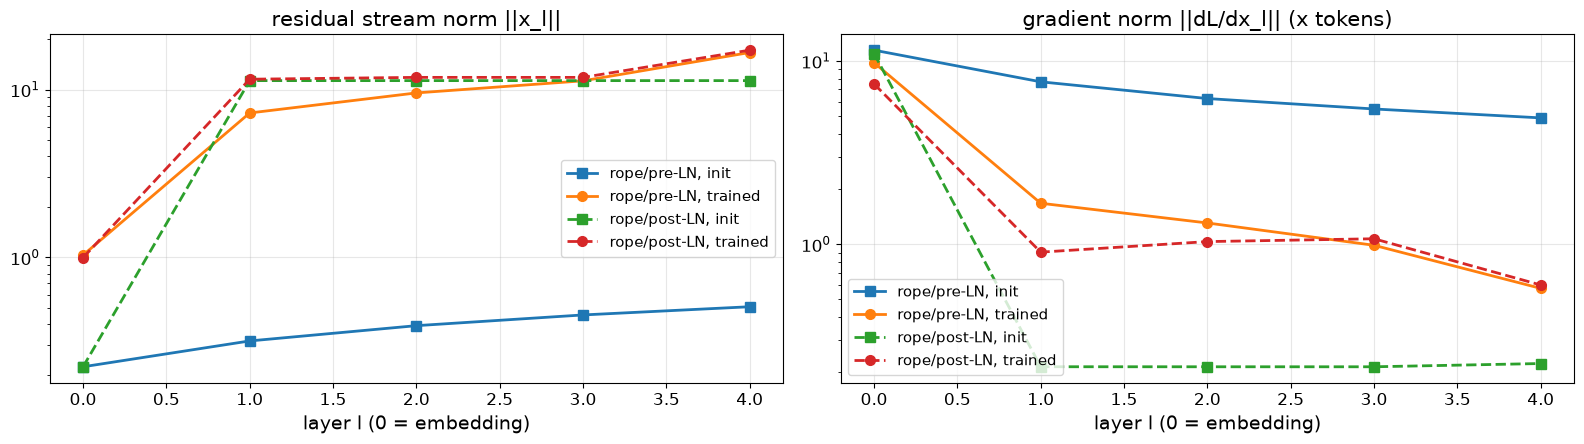

In [17]:
def residual_stats(model, n_batches=4, seed=7):
    gen = torch.Generator().manual_seed(seed); model.eval()
    L = len(model.blocks); xn, gn = np.zeros(L + 1), np.zeros(L + 1)
    for _ in range(n_batches):
        x, y = get_batch(VA, 16, S["ctx"], gen)
        outs = []
        def keep(m, i, o):
            o.retain_grad(); outs.append(o)              # хук ничего не возвращает, выход не меняется
        hooks = [model.drop.register_forward_hook(keep)] + [b.register_forward_hook(keep) for b in model.blocks]
        model.zero_grad(); loss = model(x, y)[1]; loss.backward()
        for h in hooks: h.remove()
        for l, o in enumerate(outs):
            xn[l] += o.norm(dim=-1).mean().item() / n_batches
            gn[l] += (o.grad.norm(dim=-1).mean() * x.numel()).item() / n_batches
    model.zero_grad(); model.train()
    return xn, gn

RES = {}
for name in ["rope/pre-LN", "rope/post-LN"]:
    pos, norm = name.split("/")[0], name.split("/")[1][:-3]
    torch.manual_seed(SEED); RES[(name, "init")] = residual_stats(make_gpt(pos, norm))
    RES[(name, "trained")] = residual_stats(RUNS[name]["model"])
for (name, st), (xn, gn) in RES.items():
    print(f"{name:13s} {st:7s} | ||x_l||: " + " ".join(f"{v:6.2f}" for v in xn) + " | ||dL/dx_l||: " + " ".join(f"{v:6.2f}" for v in gn))
fig, axs = plt.subplots(1, 2, figsize=(16, 4.6))
for (name, st), (xn, gn) in RES.items():
    style = ("-" if "pre" in name else "--") + ("o" if st == "trained" else "s")
    axs[0].plot(xn, style, lw=2, ms=7, label=f"{name}, {st}"); axs[1].plot(gn, style, lw=2, ms=7, label=f"{name}, {st}")
for ax, t in zip(axs, ["residual stream norm ||x_l||", "gradient norm ||dL/dx_l|| (x tokens)"]):
    ax.set_xlabel("layer l (0 = embedding)", fontsize=14); ax.set_title(t, fontsize=15); ax.set_yscale("log"); ax.legend(fontsize=11)
plt.tight_layout(); plt.show()

**Что видно.** В Pre-LN норма residual stream растёт от слоя к слою: при инициализации медленно (0,22 → 0,51), после обучения быстро (1,0 → 16,6), потому что каждый блок добавляет к потоку свой вклад и ничто его не нормирует. В Post-LN выход каждого блока проходит через LayerNorm, и при инициализации норма равна в точности \(\sqrt{d} = 11{,}31\) на всех слоях. После обучения она определяется выученными коэффициентами \(\gamma\) (11,5–17,2). Градиенты тоже ведут себя по-разному. В Pre-LN при инициализации градиент по потоку плавно убывает от эмбеддингов к верхним слоям (11,4 → 4,9) и не затухает: тождественный путь проходит через все блоки. В Post-LN при инициализации градиент на слоях 1–4 в 50 раз меньше (0,21), а на эмбеддингах большой (11,0): LayerNorm первого блока делит маленький вход с нормой 0,22 на его масштаб и усиливает градиент. Это градиенты по активациям, а не по параметрам, поэтому прямой проверкой результата Xiong et al. этот опыт не является. Но он показывает механизм: в Post-LN масштаб градиентов задают нормировки, а не тождественный путь.

## 15. Что выучила модель

### 15.1. Карты внимания

Берём модель с RoPE и Pre-LN, подаём фрагмент валидации и смотрим веса внимания всех голов первого и последнего слоя. Под картами — средний вес внимания в зависимости от расстояния назад \(i - j\) по 64 фрагментам: он показывает, какие головы локальные, а какие смотрят далеко.

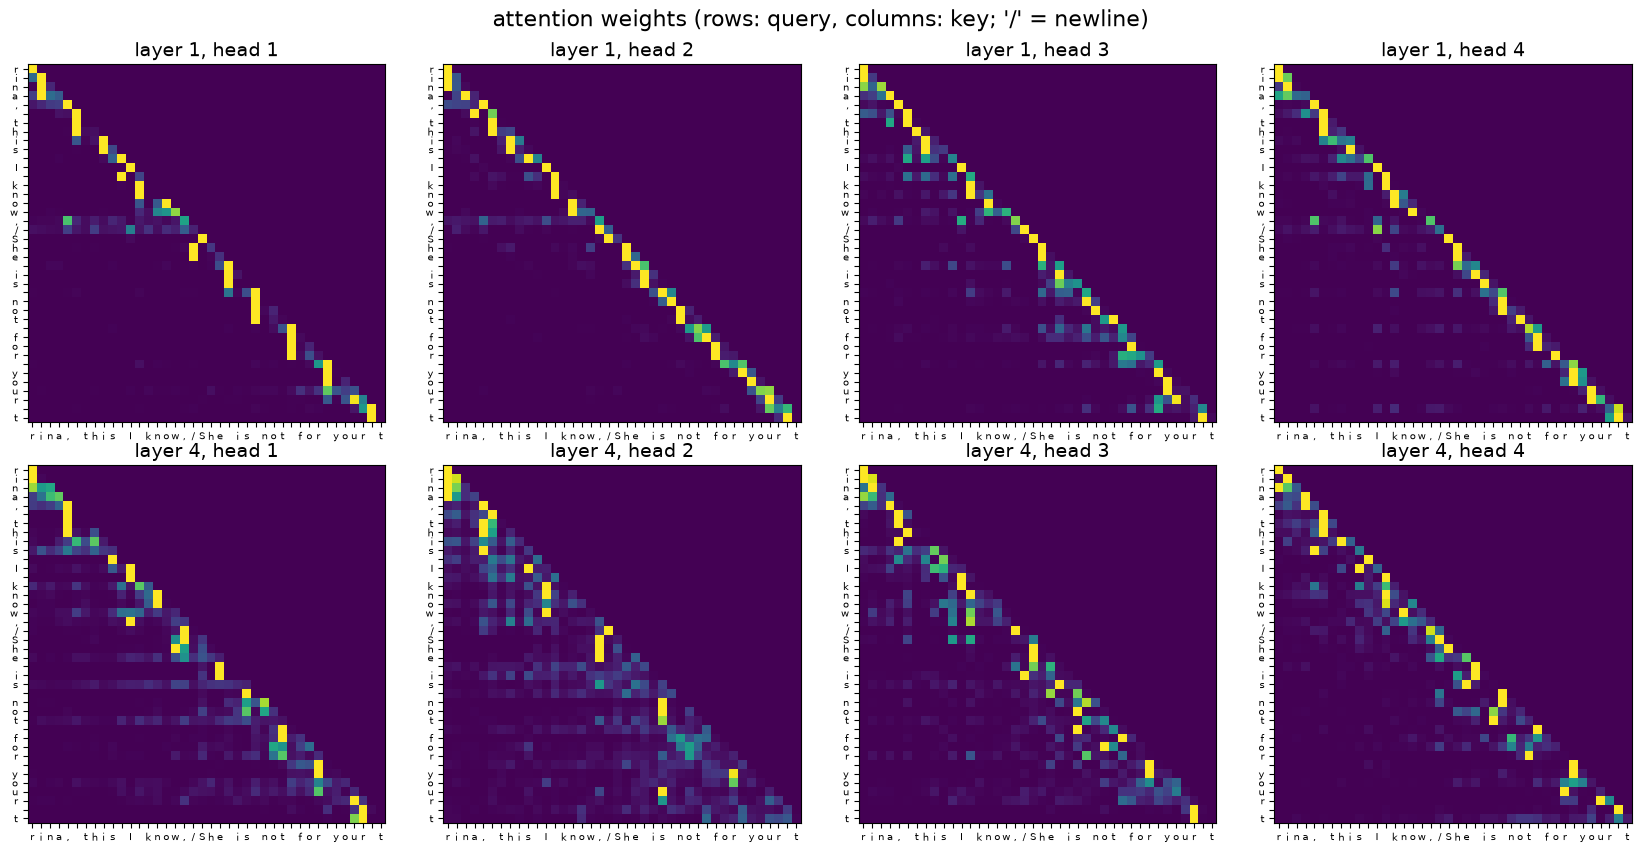

средняя дистанция внимания (позиции 64..127), символов:
  слой 1: голова 1:   5.9  голова 2:   4.9  голова 3:   8.7  голова 4:   7.1
           вес на себя (offset 0) / предыдущий символ (offset 1): 0.25/0.33  0.13/0.43  0.18/0.37  0.16/0.42
  слой 2: голова 1:  17.4  голова 2:   3.9  голова 3:   6.1  голова 4:   5.9
           вес на себя (offset 0) / предыдущий символ (offset 1): 0.08/0.10  0.26/0.31  0.09/0.18  0.14/0.26
  слой 3: голова 1:   5.7  голова 2:   5.6  голова 3:   9.1  голова 4:   3.3
           вес на себя (offset 0) / предыдущий символ (offset 1): 0.18/0.25  0.12/0.19  0.11/0.34  0.24/0.28
  слой 4: голова 1:   7.1  голова 2:  14.1  голова 3:   8.8  голова 4:   5.0
           вес на себя (offset 0) / предыдущий символ (offset 1): 0.12/0.26  0.05/0.06  0.05/0.19  0.23/0.22


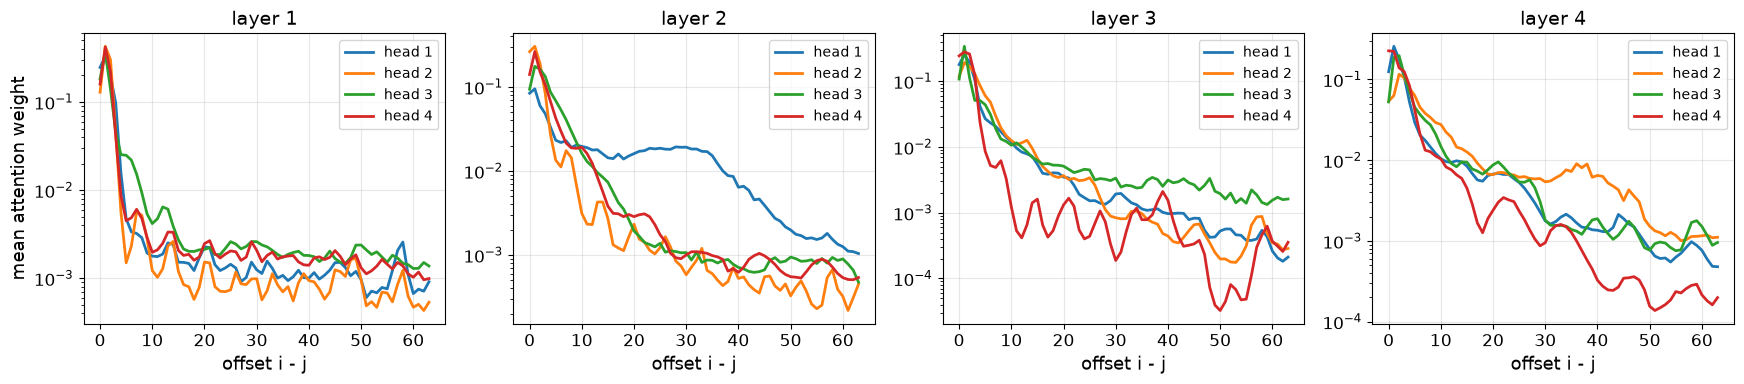

In [18]:
best = RUNS["rope/pre-LN"]["model"].eval()
txt = SH_VAL[1000:1000 + 64]
with torch.no_grad():
    _, _, attns = best(torch.tensor([[STOI[c] for c in txt]], device=DEVICE), return_attn=True)
fig, axs = plt.subplots(2, S["n_head"], figsize=(4.2 * S["n_head"], 8.6))
for r, li in enumerate([0, S["n_layer"] - 1]):
    for h in range(S["n_head"]):
        ax = axs[r, h]; ax.imshow(attns[li][0, h].cpu().numpy()[:40, :40], cmap="viridis", vmin=0, vmax=0.5)
        ax.set_xticks(range(40)); ax.set_xticklabels(list(txt[:40].replace("\n", "/")), fontsize=7)
        ax.set_yticks(range(40)); ax.set_yticklabels(list(txt[:40].replace("\n", "/")), fontsize=7)
        ax.set_title(f"layer {li + 1}, head {h + 1}", fontsize=14); ax.grid(False)
plt.suptitle("attention weights (rows: query, columns: key; '/' = newline)", fontsize=16)
plt.tight_layout(); plt.show()

gen_a = torch.Generator().manual_seed(5)
xa, _ = get_batch(VA, 64, S["ctx"], gen_a)
with torch.no_grad():
    _, _, attns = best(xa, return_attn=True)
T_ = S["ctx"]; ii, jj = torch.meshgrid(torch.arange(T_), torch.arange(T_), indexing="ij"); off = (ii - jj).to(DEVICE)
PROFILE = {}
for li in range(S["n_layer"]):
    for h in range(S["n_head"]):
        a = attns[li][:, h].mean(0)
        prof = torch.stack([a[(off == o) & (ii.to(DEVICE) >= 64)].mean() for o in range(64)]).cpu().numpy()
        PROFILE[(li, h)] = prof
        mean_dist = float((a * off.clamp_min(0)).sum(-1)[64:].mean())
        PROFILE[(li, h, "dist")] = mean_dist
print("средняя дистанция внимания (позиции 64..127), символов:")
for li in range(S["n_layer"]):
    print(f"  слой {li + 1}: " + "  ".join(f"голова {h + 1}: {PROFILE[(li, h, 'dist')]:5.1f}" for h in range(S["n_head"])))
    print(f"           вес на себя (offset 0) / предыдущий символ (offset 1): " + "  ".join(f"{PROFILE[(li, h)][0]:.2f}/{PROFILE[(li, h)][1]:.2f}" for h in range(S["n_head"])))
fig, axs = plt.subplots(1, S["n_layer"], figsize=(4.4 * S["n_layer"], 4))
for li in range(S["n_layer"]):
    for h in range(S["n_head"]):
        axs[li].semilogy(PROFILE[(li, h)], lw=2, label=f"head {h + 1}")
    axs[li].set_title(f"layer {li + 1}", fontsize=14); axs[li].set_xlabel("offset i - j", fontsize=13); axs[li].legend(fontsize=10)
axs[0].set_ylabel("mean attention weight", fontsize=13)
plt.tight_layout(); plt.show()

**Что видно.** В первом слое все головы локальны: средняя дистанция 5–9 символов, основная масса веса на самом токене и предыдущем символе (0,13–0,25 и 0,33–0,43). Это аналог n-граммного контекста. В более глубоких слоях появляются головы с широким окном: голова 1 слоя 2 (средняя дистанция 17,4) держит почти постоянный вес до смещения около 35, а голова 2 слоя 4 (14,1) почти не смотрит на соседей (0,05/0,06). На картах видно, что после символа новой строки «/» внимание рассеивается по всей предыдущей строке. Вероятно, именно головы с длинным окном дают выигрыш у KN-6, которой доступны только 5 предыдущих символов; проверить это можно, обнулив такие головы.

### 15.2. Экстраполяция длины

Модели обучены на контексте `ctx`. Применим их к окнам длины `2 ctx` и измерим bpc отдельно для позиций внутри обученного диапазона и за его пределами. Модель `learned` так применить нельзя: в её таблице нет позиций за пределами `ctx`. Для RoPE дополнительно пробуем Position Interpolation с `scale = 2` без дообучения и NTK-aware основание \(b\cdot 2^{d_h/(d_h-2)}\).

модель                   позиции 1..128     128..255
rope/pre-LN                       2.139        2.671
nope/pre-LN                       2.314        2.902
rope + PI (scale 2)               4.329        4.423
rope + NTK (s = 2)                2.175        2.286


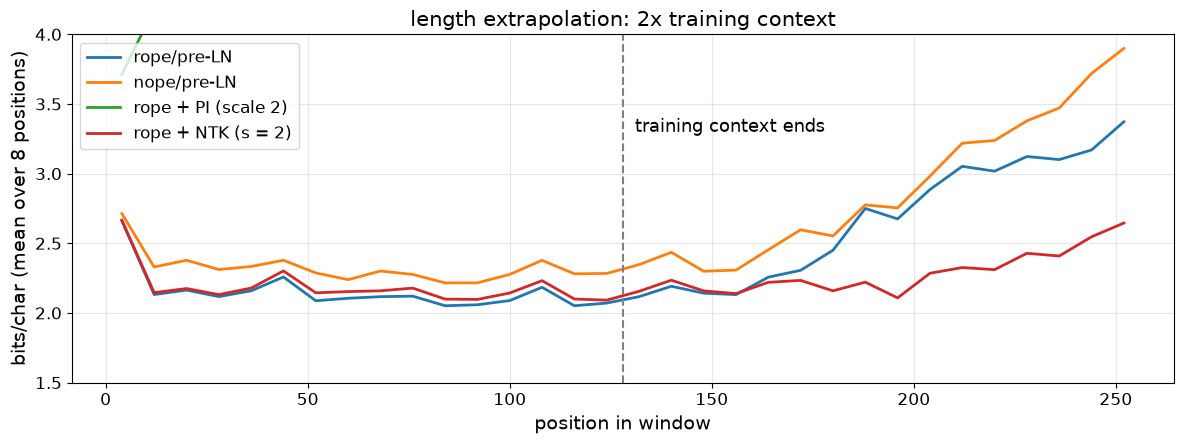

In [19]:
@torch.no_grad()
def per_position_bpc(model, ids, T, n_win=300):
    model.eval()
    starts = torch.linspace(0, len(ids) - T - 2, n_win).long()
    tot = torch.zeros(T)
    for b in range(0, n_win, 32):
        st = starts[b:b + 32]
        x = torch.stack([ids[s:s + T] for s in st]).to(DEVICE); y = torch.stack([ids[s + 1:s + T + 1] for s in st]).to(DEVICE)
        lp = F.cross_entropy(model(x)[0].float().reshape(-1, NV), y.reshape(-1), reduction="none").view(len(st), T)
        tot += lp.sum(0).cpu()
    return (tot / n_win / math.log(2)).numpy()

Tc2 = 2 * S["ctx"]
EXTRA = {}
for name in ["rope/pre-LN", "nope/pre-LN"]:
    EXTRA[name] = per_position_bpc(RUNS[name]["model"], VA, Tc2)
m_r = RUNS["rope/pre-LN"]["model"]
m_r.rope_scale = 2.0; EXTRA["rope + PI (scale 2)"] = per_position_bpc(m_r, VA, Tc2); m_r.rope_scale = 1.0
old_base = m_r.rope_base; m_r.rope_base = old_base * 2.0 ** (m_r.dh / (m_r.dh - 2))
EXTRA["rope + NTK (s = 2)"] = per_position_bpc(m_r, VA, Tc2); m_r.rope_base = old_base
c = S["ctx"]
print(f"{'модель':22s} {'позиции 1..' + str(c):>16s} {str(c) + '..' + str(Tc2 - 1):>12s}")
for name, v in EXTRA.items():
    print(f"{name:22s} {v[1:c].mean():16.3f} {v[c:].mean():12.3f}")
fig, ax = plt.subplots(figsize=(12, 4.6))
k_ = 8
for name, v in EXTRA.items():
    ax.plot(np.arange(len(v))[k_ // 2::k_][:len(v) // k_], v.reshape(-1, k_).mean(1), lw=2, label=name)
ax.axvline(c, color="gray", ls="--"); ax.text(c + 3, 3.3, "training context ends", fontsize=13)
ax.set_xlabel("position in window", fontsize=14); ax.set_ylabel("bits/char (mean over 8 positions)", fontsize=14)
ax.set_ylim(1.5, 4.0); ax.set_title("length extrapolation: 2x training context", fontsize=15); ax.legend(fontsize=12)
plt.tight_layout(); plt.show()

**Что видно.** До конца обученного контекста RoPE и NoPE ведут себя как на валидации (2,139 и 2,314 на позициях 1–127). За границей обе модели деградируют: на позициях 128–255 bpc растёт до 2,671 у RoPE и до 2,902 у NoPE, к концу окна — до 3,4 и 3,9. Формальная применимость к любой длине не означает экстраполяции. Без дообучения NTK-aware масштабирование основания почти не портит качество внутри контекста (2,175) и сильно улучшает вне его (2,286). Position Interpolation без дообучения ломает модель на всех позициях (4,33 и 4,42; кривая уходит выше верхней границы графика): сжатие высоких частот делает соседние символы неразличимыми. [Chen et al. (2023)](https://arxiv.org/abs/2306.15595) применяют PI с коротким дообучением; задание 6 предлагает проверить, что оно исправляет.

### 15.3. KV-кэш и генерация

При генерации без кэша на каждом шаге заново считаются ключи и значения всего префикса. С кэшем (раздел 6.2) прошлые \(K, V\) хранятся, и шаг обрабатывает только новый токен; для RoPE нужно передать абсолютную позицию нового токена (`offset`). Проверим, что логиты совпадают, и сравним время. Генерация ограничена `ctx` символами, чтобы не выходить за обученный диапазон.

In [20]:
@torch.no_grad()
def generate(model, prompt, n_new, temperature=1.0, use_cache=True, seed=0, return_logits=False):
    model.eval(); gen = torch.Generator(device=DEVICE).manual_seed(seed)
    idx = torch.tensor([[STOI[c] for c in prompt]], device=DEVICE)
    out_logits = []
    caches = [dict() for _ in model.blocks] if use_cache else None
    logits = model(idx, caches=caches)[0][:, -1] if use_cache else None
    for t in range(n_new):
        if not use_cache:
            logits = model(idx[:, -model.ctx:])[0][:, -1]
        out_logits.append(logits.float())
        p = F.softmax(logits.float() / temperature, -1)
        nxt = torch.multinomial(p, 1, generator=gen)
        idx = torch.cat([idx, nxt], 1)
        if use_cache:
            logits = model(nxt, caches=caches, offset=idx.shape[1] - 1)[0][:, -1]
    text = decode(idx[0].tolist())
    return (text, torch.cat(out_logits)) if return_logits else text

prompt = "ROMEO:\n"
n_new = S["ctx"] - len(prompt)
for name in ["rope/pre-LN", "learned/pre-LN"]:
    m_ = RUNS[name]["model"]
    t0 = time.time(); t1, l1 = generate(m_, prompt, n_new, use_cache=False, return_logits=True); dt0 = time.time() - t0
    t0 = time.time(); t2, l2 = generate(m_, prompt, n_new, use_cache=True, return_logits=True); dt1 = time.time() - t0
    print(f"{name:15s}: max |логиты с кэшем - без| = {(l1 - l2).abs().max():.1e}, тексты совпадают: {t1 == t2}; время {dt0:.2f} с без кэша, {dt1:.2f} с с кэшем")

for tau in [0.5, 0.8, 1.0]:
    print(f"\n--- Mini-GPT (RoPE), tau = {tau} ---")
    print(generate(best, prompt, n_new, temperature=tau, seed=1))

rope/pre-LN    : max |логиты с кэшем - без| = 1.9e-05, тексты совпадают: True; время 0.35 с без кэша, 0.14 с с кэшем


learned/pre-LN : max |логиты с кэшем - без| = 2.0e-05, тексты совпадают: True; время 0.24 с без кэша, 0.10 с с кэшем

--- Mini-GPT (RoPE), tau = 0.5 ---
ROMEO:
What say you the country?

CAPULET:
Not with the Duke of York, and so rain.

Second Gentleman:
What, grant the word?

DUK

--- Mini-GPT (RoPE), tau = 0.8 ---


ROMEO:
What stays with aught, that means thy shame?

KING EDWARD IV:
Why, my lord. O, a half a heavy wos not with the
woor doth 

--- Mini-GPT (RoPE), tau = 1.0 ---
ROMEO:
What; those place again, I then; you can make a sacrifity
Shich were in within your grace strangs not.

MENENIUS:
Madam, 


**Что видно.** Генерация с KV-кэшем выдаёт те же тексты, что и полный пересчёт, а логиты отличаются не больше чем на \(2\cdot 10^{-5}\) — это округление float32 при другом порядке суммирования. Кэш ускоряет генерацию в 2,4–2,5 раза (0,35 → 0,14 с для RoPE). Выигрыш растёт с длиной: без кэша каждый шаг пересчитывает весь префикс. Образцы показывают роль температуры. При \(\tau = 0{,}5\) получаются осмысленные строки и реплики с правильными именами персонажей (CAPULET, DUKE). При \(\tau = 1\) появляются несуществующие слова (sacrifity, strangs). Формат пьесы модель выучила при любой температуре.

## 16. Сводная таблица

In [21]:
print(f"{'модель':44s} {'параметров':>11s} {'val bpc':>8s}")
for name, v in L1_REF.items():
    print(f"{('лекция 1: ' + name):44s} {'':>11s} {v:8.3f}")
SUMMARY = {}
for name, r in RUNS.items():
    SUMMARY[name] = r["log"]["val"][-1][1]
    print(f"{('Mini-GPT ' + name):44s} {r['params']:>11,} {SUMMARY[name]:8.3f}")
best_name = min(SUMMARY, key=SUMMARY.get)
print(f"\nлучший вариант: {best_name}, {SUMMARY[best_name]:.3f} бит/символ; LSTM лекции 1: {L1_REF['LSTM, 351 тыс. параметров']:.3f}")
print(f"обучение каждого варианта: {S['steps']} шагов по {S['bs']} x {S['ctx']} = {S['steps'] * S['bs'] * S['ctx'] / 1e6:.1f} млн символов "
      f"(~{S['steps'] * S['bs'] * S['ctx'] / len(TR):.1f} эпохи)")
print(f"время работы блокнота: {(time.time() - T_START) / 60:.1f} мин на {DEVICE}")

модель                                        параметров  val bpc
лекция 1: равномерное распределение                         6.022
лекция 1: Kneser–Ney, n = 6                                 2.248
лекция 1: RNN (tanh), 103 тыс. параметров                   2.262
лекция 1: LSTM, 351 тыс. параметров                         2.193
Mini-GPT rope/pre-LN                             801,664    2.124
Mini-GPT learned/pre-LN                          818,048    2.194
Mini-GPT nope/pre-LN                             801,664    2.300
Mini-GPT rope/post-LN                            801,408    2.196

лучший вариант: rope/pre-LN, 2.124 бит/символ; LSTM лекции 1: 2.193
обучение каждого варианта: 3000 шагов по 32 x 128 = 12.3 млн символов (~12.2 эпохи)
время работы блокнота: 32.6 мин на cpu


**Что видно.** Все четыре трансформера лучше равномерной модели почти на 4 бита. Mini-GPT с RoPE и Pre-LN (2,124) — лучшая модель обеих лекций: она обходит KN-6 на 0,12 бита и LSTM на 0,07 бита. Вариант с обучаемыми позициями равен LSTM, NoPE хуже KN-6. Каждая модель видела 12,3 млн символов (около 12 эпох). Весь блокнот на CPU выполнился за 32,6 минуты; на GPU-ветке модель больше (\(d = 384\), 6 слоёв, контекст 256), и её результаты здесь не проверены.

# Выводы

1. Attention — это дифференцируемый поиск по словарю: веса \(\mathrm{softmax}(QK^\top/\sqrt{d_k})\) суммируются в 1, а частный случай с гауссовым ядром в точности совпадает с регрессией Надарая–Ватсона (раздел 10.2, расхождение \(3\cdot 10^{-13}\)). Реализация с нуля и ручной обратный проход совпадают с PyTorch до \(10^{-16}\).
2. Деление на \(\sqrt{d_k}\) делает дисперсию логитов равной 1 при любом \(d_k\). Без него при \(d_k = 1024\) внимание почти one-hot (энтропия 0,20 бита из 7), и якобиан softmax в 1,9 раза меньше, чем с делением (раздел 9).
3. Self-attention без позиций эквивариантен к перестановкам (ошибка \(4\cdot 10^{-16}\)); причинная маска нарушает эквивариантность, поэтому декодер NoPE учится, хотя медленнее и хуже: 2,300 бита против 2,124 у RoPE.
4. RoPE делает логит функцией только разности позиций (разброс \(10^{-13}\)) и не меняет норм. Затухание с расстоянием есть для согласованных \(q, k\), но не для случайных. На Tiny Shakespeare RoPE лучше обучаемых позиций (2,124 против 2,194) при меньшем числе параметров.
5. Формулы \(12Ld^2 + 13Ld\) для параметров и \(2N_{\text{mm}}T + 4LT^2d\) для FLOPs точно совпадают с измерением (801 664 параметра, 237,0 MFLOPs); attention-слагаемое при \(T = 128\), \(d = 128\) — 14 % вычислений.
6. Mini-GPT с 0,8 млн параметров после 3000 шагов на CPU даёт 2,124 бита на символ — лучше KN-6 (2,248) и LSTM (2,193) из лекции 1. Выигрыш у LSTM небольшой, а разрыв между обучением и валидацией (около 0,37 бита) показывает, что для большей модели нужна регуляризация.
7. В Pre-LN норма residual stream растёт с глубиной, а градиент проходит по тождественному пути без затухания. В Post-LN норма зафиксирована LayerNorm на \(\sqrt{d}\), а градиенты внутренних слоёв при инициализации в 50 раз меньше, чем на эмбеддингах. При 4 слоях и прогреве Post-LN обучился почти так же хорошо (2,196).
8. Ранние слои учат локальные головы (предыдущий символ, окно 5–9 символов), глубокие — головы с окном в десятки символов.
9. Ни RoPE, ни NoPE не экстраполируют на удвоенный контекст без дообучения. NTK-aware масштабирование основания помогает даже без дообучения (2,286 против 2,671), а PI без дообучения ломает модель.
10. KV-кэш даёт те же тексты, что и полный пересчёт, и ускоряет генерацию в 2,5 раза уже на 120 новых токенах. Платой за ускорение служит память, которая растёт линейно с длиной, числом слоёв и \(d\).
11. Все числа получены в режиме CPU `FAST_DEV_RUN` на одном зерне. Ветка GPU с большой моделью (\(d = 384\), 6 слоёв, контекст 256, 5000 шагов) не проверялась, и её результаты могут отличаться.

# Контрольные вопросы

1. Какое узкое место архитектуры encoder–decoder устраняет attention? Как меняется длина пути градиента от выхода декодера до состояния кодировщика?
2. Запишите аддитивное внимание Багданау и мультипликативное внимание Луонга. Какое из них сводится к матричному умножению \(QK^\top\)?
3. Компоненты \(q, k \in \mathbb{R}^{256}\) независимы, \(\mathcal{N}(0, 1)\). Каково стандартное отклонение \(q^\top k\) без масштабирования и после деления на \(\sqrt{d_k}\)?
4. Логиты \(z = (2, 0, 0, 0)\). Найдите \(a = \mathrm{softmax}(z)\) и диагональный элемент \(J_{11}\) якобиана.
5. Докажите, что \(J\mathbf{1} = 0\) и \(\|J\|_2 \le 1/2\). При каком \(a\) граница достигается?
6. Почему строка логитов, целиком заполненная \(-\infty\), даёт NaN, и почему в причинной маске такого не бывает?
7. Сколько FLOPs стоит \(QK^\top\) для одной головы при \(T = 1024\), \(d_h = 64\)? Сколько памяти занимает матрица \(A\) в fp16 для 12 голов одного слоя?
8. \(d = 768\), \(H = 12\). Какова размерность головы и максимальный ранг \(W_{QK}^h\)? Почему конкатенация голов с \(W_O\) равна сумме вкладов голов?
9. Докажите, что \(\mathrm{SA}(PX) = P\,\mathrm{SA}(X)\) для self-attention без маски. Что меняет причинная маска?
10. Сколько параметров в блоке трансформера с \(d = 512\) по формуле \(12d^2 + 13d\)?
11. Оцените число параметров GPT-2 small: \(L = 12\), \(d = 768\), \(V = 50257\), обучаемые позиции на 1024, weight tying.
12. Сколько FLOPs нужно, чтобы обучить модель с \(N = 124\) млн параметров на \(10^{10}\) токенов по оценке \(6ND\)?
13. Какую долю составляет attention-слагаемое \(4LTd\) от \(2\cdot 12Ld^2\) при \(d = 768\), \(T = 1024\)?
14. Что показали Xiong et al. о градиентах Post-LN при инициализации и зачем Post-LN нужен прогрев learning rate?
15. Вычислите LayerNorm и RMSNorm (без \(\gamma, \beta\), \(\varepsilon \to 0\)) для \(x = (2, 2, 2, 2)\) и \(x = (1, -1, 1, -1)\).
16. Какой должна быть скрытая размерность SwiGLU-FFN при \(d = 768\), чтобы число параметров совпало с FFN \(d \to 4d \to d\) без смещений?
17. Докажите \(\langle R_m q, R_n k\rangle = \langle q, R_{n-m}k\rangle\) для RoPE. Почему значения \(v\) не поворачивают?
18. RoPE, \(d_h = 64\), \(b = 10000\). Каковы длины волн первой и последней пары? У скольких пар длина волны меньше 128?
19. Модель с RoPE обучена на \(L = 2048\), нужна длина 8192. Какую позицию «увидит» токен 8000 при Position Interpolation? Каким будет новое основание при NTK-aware масштабировании для \(d_h = 128\)?
20. Почему модель с обучаемыми позициями нельзя применить к контексту длиннее обученного, а модели с RoPE и NoPE — можно? Что в разделе 15.2 произошло с качеством за границей контекста?
21. Сколько памяти занимает KV-кэш одной последовательности длины 4096 для модели с \(L = 32\), \(d = 4096\) в fp16?
22. Сколько параметров экономит weight tying при \(V = 50257\), \(d = 768\)? Как в разделе 15.3 проверяется корректность KV-кэша?

## Ответы

1. Кодировщик сжимает всё предложение в один вектор фиксированной длины. Attention даёт декодеру на каждом шаге взвешенную сумму всех состояний кодировщика; путь градиента от \(y_t\) до любого \(h_j\) имеет длину 1 вместо \(S - j\).
2. Багданау: \(e_{tj} = v^\top\tanh(Ws_{t-1} + Uh_j)\). Луонг: \(e_{tj} = s_t^\top W h_j\) (вариант general) или \(s_t^\top h_j\) (dot). Мультипликативное для всех пар сразу — это одно умножение матриц \(QK^\top\).
3. \(\mathrm{Var} = d_k = 256\), стандартное отклонение 16; после деления на \(\sqrt{256} = 16\) — 1.
4. \(a_1 = e^2/(e^2 + 3) = 7{,}389/10{,}389 \approx 0{,}711\), остальные \(\approx 0{,}096\). \(J_{11} = a_1(1 - a_1) \approx 0{,}205\).
5. \(J\mathbf{1} = a - a\,(a^\top\mathbf{1}) = a - a = 0\). \(u^\top Ju = \mathrm{Var}_{i\sim a}(u_i) \le (\max u - \min u)^2/4 \le 2/4\) при \(\|u\| = 1\). Равенство при \(a = (\tfrac12, \tfrac12, 0, \dots)\), \(u = (1, -1, 0, \dots)/\sqrt2\).
6. \(\exp(-\infty) = 0\) во всех элементах, softmax делит \(0\) на \(0\). В причинной маске диагональ \(j = i\) всегда разрешена, в строке есть хотя бы один конечный логит.
7. \(2T^2d_h = 2\cdot 1024^2\cdot 64 \approx 1{,}34\cdot 10^{8}\) FLOPs. \(A\): \(12\cdot 1024^2\cdot 2\) байта \(\approx 25{,}2\) МБ на слой и последовательность.
8. \(d_h = 64\), ранг \(W_{QK}^h \le 64\). \([\mathrm{head}_1,\dots,\mathrm{head}_H]W_O = \sum_h \mathrm{head}_h W_O^h\), где \(W_O^h\) — блок из \(d_h\) строк \(W_O\): это правило умножения блочных матриц.
9. \(\mathrm{softmax}(PSP^\top) = P\,\mathrm{softmax}(S)P^\top\) (softmax по строкам переставляет строки и элементы внутри строк согласованно), и \(P^\top P = I\). Причинная маска \(M\) не инвариантна: \(PMP^\top \ne M\), поэтому эквивариантность пропадает, и позиция \(i\) видит ровно \(i\) токенов. В разделе 10.1 ошибка без маски \(\sim 10^{-16}\), с маской — порядка единицы.
10. \(12\cdot 512^2 + 13\cdot 512 = 3\,145\,728 + 6\,656 = 3\,152\,384\).
11. Блоки \(12\cdot(12\cdot 768^2 + 13\cdot 768) = 85\,054\,464\); токены \(50257\cdot 768 = 38\,597\,376\); позиции \(1024\cdot 768 = 786\,432\); финальный LayerNorm \(1536\). Итого \(124\,439\,808 \approx 124\) млн.
12. \(6\cdot 1{,}24\cdot 10^{8}\cdot 10^{10} \approx 7{,}4\cdot 10^{18}\) FLOPs.
13. \(T/(6d) = 1024/4608 \approx 22\%\).
14. В Post-LN ожидаемые градиенты параметров у выходного слоя при инициализации велики, и большой learning rate в начале дестабилизирует обучение; прогрев постепенно увеличивает шаг, пока модель не уйдёт из этой области. В Pre-LN градиенты при инициализации хорошо ведут себя, и прогрев можно убрать.
15. \((2,2,2,2)\): LayerNorm даёт \(0\) (среднее 2, дисперсия 0; при \(\varepsilon > 0\) — нулевой вектор), RMSNorm — \((1,1,1,1)\). \((1,-1,1,-1)\): среднее 0, \(\sigma = 1\), RMS = 1 — оба дают \((1,-1,1,-1)\).
16. \(3dh = 8d^2 \Rightarrow h = 8d/3 = 2048\).
17. \(R_m^\top R_n = R_{-m}R_n = R_{n-m}\) для поворотов в одной плоскости, а блочно-диагональная \(R\) действует поблочно. Логит должен зависеть от разности позиций, и этого достаточно, чтобы повернуть \(q\) и \(k\). Значения складываются с весами, их поворот только исказил бы выход.
18. \(2\pi\theta_i^{-1} = 2\pi\cdot 10^{i/8}\): для \(i = 0\) — \(2\pi \approx 6{,}3\) токена, для \(i = 31\) — \(2\pi\cdot 10^{31/8} \approx 47\,117\). Условие \(10^{i/8} < 128/2\pi \approx 20{,}4\) даёт \(i \le 10\), то есть 11 пар (правая панель рисунка в разделе 12.3).
19. PI: \(8000/4 = 2000\), внутри обученного диапазона. NTK: \(b' = 10000\cdot 4^{128/126} \approx 10000\cdot 4{,}089 \approx 40\,900\).
20. В таблице обучаемых позиций просто нет строк для позиций \(\ge L\). RoPE и NoPE формально определены на любой длине. В разделе 15.2 обе модели за границей контекста деградируют: на позициях 128–255 bpc 2,671 у RoPE и 2,902 у NoPE против 2,139 и 2,314 внутри. Применимость не равна экстраполяции. NTK-основание без дообучения даёт 2,286, а PI без дообучения ломает модель на всех позициях (4,33).
21. \(2\cdot 32\cdot 4096\cdot 4096\cdot 2\) байта \(= 2^{31}\) байт \(= 2\) ГиБ.
22. Не нужна отдельная выходная матрица: экономия \(50257\cdot 768 \approx 38{,}6\) млн параметров, около трети GPT-2 small. В разделе 15.3 генерация с кэшем и без него выдаёт одинаковые тексты, а логиты отличаются не больше чем на \(2\cdot 10^{-5}\) (округление float32); кэш ускоряет генерацию в 2,5 раза.

# Задания

1. **ALiBi.** Добавьте в `MHA` штраф \(-\lambda_h(i - j)\) с наклонами \(\lambda_h = 2^{-8h/H}\). Обучите Mini-GPT с ALiBi и сравните с RoPE и NoPE по bpc на контексте `ctx` и на `2 ctx`, `4 ctx` (как в разделе 15.2).
2. **Блок LLaMA.** Замените LayerNorm на RMSNorm, а FFN — на SwiGLU со скрытой размерностью \(\tfrac83 d\), сохранив число параметров. Сравните bpc и время шага с базовым блоком при одинаковом бюджете шагов.
3. **Прогрев и Post-LN.** Обучите Post-LN и Pre-LN без прогрева и с прогревом при \(\mathrm{lr} \in \{10^{-3}, 3\cdot 10^{-3}, 10^{-2}\}\) и 4, 8 слоях. Постройте таблицу «сошлось / разошлось» и финальный bpc. Совпадает ли картина с выводами Xiong et al.?
4. **Индукционные головы.** Сгенерируйте последовательности вида «случайные 50 символов, повторённые дважды». Измерьте потерю Mini-GPT на второй половине и найдите головы, которые на позиции \(i\) смотрят на символ, следующий за предыдущим вхождением \(x_i\). Сравните модели с 1 и 2 слоями.
5. **GQA.** Реализуйте grouped-query attention: \(H\) голов запросов и \(G < H\) голов ключей и значений. Измерьте размер KV-кэша, скорость генерации и bpc при \(G \in \{1, 2, 4\}\).
6. **Дообучение с PI.** Дообучите RoPE-модель на контексте `2 ctx` в течение 200 шагов с PI (`rope_scale = 2`), с NTK-основанием и без изменений. Сравните кривые bpc по позициям с разделом 15.2.
7. **Масштабирование.** Обучите модели с \(d \in \{64, 128, 256\}\) и \(n_{\text{layer}} \in \{2, 4\}\) при одинаковом числе токенов. Постройте bpc от числа параметров без эмбеддингов в log-масштабе и сравните измеренное время шага с оценкой \(6N\) FLOPs на токен.
8. **Подсловные токены.** Обучите Mini-GPT на токенах BPE-1000 из лекции 1 вместо символов. Переведите потерю в биты на байт и сравните с символьной моделью при одинаковом числе обучающих байтов.

# Источники

Данные и код

- A. Karpathy. char-rnn, Tiny Shakespeare. https://github.com/karpathy/char-rnn
- A. Karpathy. nanoGPT. https://github.com/karpathy/nanoGPT

Attention и seq2seq

- I. Sutskever, O. Vinyals, Q. V. Le. Sequence to Sequence Learning with Neural Networks, 2014. https://arxiv.org/abs/1409.3215
- K. Cho et al. Learning Phrase Representations using RNN Encoder-Decoder for Statistical Machine Translation, 2014. https://arxiv.org/abs/1406.1078
- D. Bahdanau, K. Cho, Y. Bengio. Neural Machine Translation by Jointly Learning to Align and Translate, 2014. https://arxiv.org/abs/1409.0473
- M.-T. Luong, H. Pham, C. D. Manning. Effective Approaches to Attention-based Neural Machine Translation, 2015. https://arxiv.org/abs/1508.04025
- E. A. Nadaraya. On Estimating Regression. Theory of Probability & Its Applications, 1964. https://doi.org/10.1137/1109020
- A. Zhang et al. Dive into Deep Learning, 11.2 Attention Pooling by Similarity. https://d2l.ai/chapter_attention-mechanisms-and-transformers/attention-pooling.html
- A. Vaswani et al. Attention Is All You Need, 2017. https://arxiv.org/abs/1706.03762
- T. Dao et al. FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness, 2022. https://arxiv.org/abs/2205.14135
- N. Elhage et al. A Mathematical Framework for Transformer Circuits, 2021. https://transformer-circuits.pub/2021/framework/index.html

Блок трансформера

- J. L. Ba, J. R. Kiros, G. E. Hinton. Layer Normalization, 2016. https://arxiv.org/abs/1607.06450
- R. Xiong et al. On Layer Normalization in the Transformer Architecture, 2020. https://arxiv.org/abs/2002.04745
- B. Zhang, R. Sennrich. Root Mean Square Layer Normalization, 2019. https://arxiv.org/abs/1910.07467
- N. Shazeer. GLU Variants Improve Transformer, 2020. https://arxiv.org/abs/2002.05202
- M. Geva et al. Transformer Feed-Forward Layers Are Key-Value Memories, 2021. https://arxiv.org/abs/2012.14913
- O. Press, L. Wolf. Using the Output Embedding to Improve Language Models, 2017. https://arxiv.org/abs/1608.05859
- J. Kaplan et al. Scaling Laws for Neural Language Models, 2020. https://arxiv.org/abs/2001.08361

Позиционное кодирование

- J. Su et al. RoFormer: Enhanced Transformer with Rotary Position Embedding, 2021. https://arxiv.org/abs/2104.09864
- O. Press, N. A. Smith, M. Lewis. Train Short, Test Long: Attention with Linear Biases Enables Input Length Extrapolation, 2021. https://arxiv.org/abs/2108.12409
- S. Chen et al. Extending Context Window of Large Language Models via Positional Interpolation, 2023. https://arxiv.org/abs/2306.15595
- B. Peng et al. YaRN: Efficient Context Window Extension of Large Language Models, 2023. https://arxiv.org/abs/2309.00071
- A. Haviv et al. Transformer Language Models without Positional Encodings Still Learn Positional Information, 2022. https://arxiv.org/abs/2203.16634
- A. Kazemnejad et al. The Impact of Positional Encoding on Length Generalization in Transformers, 2023. https://arxiv.org/abs/2305.19466

Архитектуры

- J. Devlin et al. BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding, 2018. https://arxiv.org/abs/1810.04805
- A. Radford et al. Language Models are Unsupervised Multitask Learners (GPT-2), 2019. https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf
- C. Raffel et al. Exploring the Limits of Transfer Learning with a Unified Text-to-Text Transformer (T5), 2019. https://arxiv.org/abs/1910.10683
- H. Touvron et al. LLaMA: Open and Efficient Foundation Language Models, 2023. https://arxiv.org/abs/2302.13971